In [13]:
# News Articles — Analysis
# Sentiment | Categories | Named Persons | Content Analysis | Topic Modeling

# This notebook performs comprehensive NLP analysis on a multi-source news articles dataset covering ~6 months from 5 major outlets:
# Fox News, CNN, The Guardian, PBS NewsHour, Al Jazeera.

# Models used (all open-source):
# - j-hartmann/sentiment-roberta-large-english-3-classes — transformer sentiment (Hartmann et al., 2023)
# - facebook/bart-large-mnli — zero-shot topic classification
# - spaCy en_core_web_trf — named entity recognition
# - BERTopic (all-MiniLM-L6-v2 + HDBSCAN) — unsupervised topic modeling

In [14]:
# ============================================================
# Installation
# ============================================================

!pip install -q textstat wordcloud bertopic sentence-transformers rapidfuzz
!python -m spacy download en_core_web_trf -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.4/457.4 MB 4.2 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_trf')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [15]:
# ============================================================
# Imports & Configuration
# ============================================================

import os, re, gc, warnings
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from tqdm.auto import tqdm

# NLP
import spacy
from transformers import pipeline as hf_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
import textstat
from wordcloud import WordCloud, STOPWORDS
from rapidfuzz import fuzz

# Topic modelling
from bertopic import BERTopic

# Statistical tests
from scipy import stats
from sklearn.metrics import cohen_kappa_score, confusion_matrix, classification_report

import torch

warnings.filterwarnings("ignore")
tqdm.pandas()

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams.update({
    "figure.figsize": (14, 7),
    "figure.dpi": 100,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
})

# Switches
TEST_MODE = True            # True  -> small test subset
                            # False -> full dataset
SAMPLE_PER_SOURCE = 10      # articles per source in test mode
RANDOM_STATE = 42

# path
DATASET_PATH = "/kaggle/input/datasets/arshjaved/news-articles/articles.parquet"

# model names
SENTIMENT_MODEL  = "j-hartmann/sentiment-roberta-large-english-3-classes"
ZS_MODEL         = "facebook/bart-large-mnli"
SPACY_MODEL      = "en_core_web_trf"

# Chunking config for long-article sentiment
# RoBERTa max is 512 tokens (~380 words). We split articles into overlapping
# chunks so nothing is silently truncated.
CHUNK_MAX_TOKENS  = 400     # tokens per chunk (leave headroom for special tokens)
CHUNK_OVERLAP     = 50      # overlapping tokens between consecutive chunks

# Chunking config for zero-shot classification
# BART-MNLI max is 1024 tokens. The hypothesis template adds ~20-30 tokens
# and tokenizer encode->decode->encode round-trip can expand tokens by up to
# ~29% due to boundary effects and whitespace normalization.
ZS_CHUNK_MAX_TOKENS = 600
ZS_CHUNK_OVERLAP    = 100   # overlap between chunks

# batch sizes
BATCH_SENTIMENT = 32
BATCH_ZS        = 8
BATCH_NER       = 8         # for spaCy nlp.pipe()

# Quality filtering
QUALITY_THRESHOLD = 0.3     # drop articles below this quality_score

# Statistical significance
ALPHA = 0.05                # significance level
N_COMPARISONS_SOURCES = 10  # C(5,2) pairwise comparisons for 5 sources
BONFERRONI_ALPHA = ALPHA / N_COMPARISONS_SOURCES

# zero-shot candidate categories
CANDIDATE_CATEGORIES = [
    "Politics & Government",
    "Business & Economy",
    "International Affairs & Diplomacy",
    "Science & Technology",
    "Health & Medicine",
    "Sports",
    "Entertainment & Culture",
    "Crime & Justice",
    "Environment & Climate",
    "Education",
    "Military & Defense",
]

DEVICE = 0 if torch.cuda.is_available() else -1
print(f"Device: {'GPU' if DEVICE == 0 else 'CPU'}")
print(f"TEST_MODE: {TEST_MODE}")
if TEST_MODE:
    print("Running on small sample — results are for pipeline validation only.")

Device: GPU
TEST_MODE: True
Running on small sample — results are for pipeline validation only.


In [16]:
# ============================================================
# building dataset
# ============================================================

df_full = pd.read_parquet(DATASET_PATH)
print(f"Raw dataset : {len(df_full):,} rows x {df_full.shape[1]} columns")

# Deduplicate by canonical URL
df_full = df_full.drop_duplicates(subset="canonical_url", keep="first").reset_index(drop=True)
print(f"After URL dedup : {len(df_full):,} rows")

# Deduplicate by content (catches same article published under different URL paths)
df_full = df_full.drop_duplicates(subset="content", keep="first").reset_index(drop=True)
print(f"After content dedup : {len(df_full):,} rows")

# Parse dates
df_full["pub_date"] = pd.to_datetime(df_full["published_date"], format="mixed", utc=True)
df_full["pub_month"] = df_full["pub_date"].dt.to_period("M")

# Build working dataframe
if TEST_MODE:
    df = (
        df_full
        .groupby("source", group_keys=False)
        .apply(lambda g: g.sample(n=min(SAMPLE_PER_SOURCE, len(g)), random_state=RANDOM_STATE))
        .reset_index(drop=True)
    )
else:
    df = df_full.copy()

print(f"\nWorking dataset : {len(df):,} articles")
print(f"Sources : {df['source'].unique().tolist()}")
print(f"Date range : {df['pub_date'].min().strftime('%Y-%m-%d')} to {df['pub_date'].max().strftime('%Y-%m-%d')}")
print("\nArticles per source:")
print(df["source"].value_counts().to_string())

Raw dataset : 63,267 rows x 24 columns
After URL dedup : 56,286 rows
After content dedup : 56,256 rows

Working dataset : 50 articles
Sources : ['Al Jazeera', 'CNN', 'Fox News', 'PBS NewsHour', 'The Guardian']
Date range : 2025-07-16 to 2026-01-09

Articles per source:
source
Al Jazeera      10
CNN             10
Fox News        10
PBS NewsHour    10
The Guardian    10


In [17]:
# ============================================================
# Preprocessing & Cleaning
# ============================================================

def _clean_aljazeera_recommended(text: str) -> str:
    """Remove inline Recommended Stories blocks embedded mid-article."""
    text = re.sub(
        r"\n?Recommended Stories\nlist of \d+ items(?:- list \d+ of \d+[^\n]*\n?)+",
        "\n", text,
    )
    text = re.sub(
        r"\n?Recommended Stories\nlist of \d+ items?(?:end of list)?",
        "\n", text,
    )
    return text

def _clean_published_on_prefix(text: str) -> str:
    """Strip 'Published On DD Mon YYYY' prefix from Al Jazeera articles."""
    return re.sub(r"^Published On \d{1,2} \w+ \d{4}\n", "", text)

def _clean_pbs_watch(text: str) -> str:
    """Remove inline WATCH: <description> lines from PBS NewsHour."""
    return re.sub(r"\n?WATCH:[^\n]*\n?", "\n", text)

def _clean_cnn_boilerplate(text: str) -> str:
    """Remove CNN newsletter cross-promo sentences."""
    text = re.sub(r"A version of this story appeared in CNN[^\n]*\n?", "", text)
    text = re.sub(r"Sign up for CNN[^\n]*newsletter[^\n]*\n?", "", text, flags=re.IGNORECASE)
    return text

def _clean_fox_boilerplate(text: str) -> str:
    """Remove Fox News app/newsletter promos and common footer lines."""
    text = re.sub(r"CLICK HERE TO GET THE FOX NEWS APP[^\n]*\n?", "", text)
    text = re.sub(r"GET FOX BUSINESS ON THE GO[^\n]*\n?", "", text)
    text = re.sub(r"Fox News['\u2019]? .* contributed to this report\.?\n?", "", text)
    text = re.sub(r"SIGN UP FOR OUR[^\n]*NEWSLETTER[^\n]*\n?", "", text, flags=re.IGNORECASE)
    return text

def _clean_guardian_boilerplate(text: str) -> str:
    """Remove Guardian-specific footer/promo text."""
    text = re.sub(r"skip past newsletter promotion.*?after newsletter promotion", "", text,
                  flags=re.DOTALL | re.IGNORECASE)
    text = re.sub(r"Sign up to [^\n]*\n?Free newsletter[^\n]*\n?", "", text, flags=re.IGNORECASE)
    return text

def _clean_general_boilerplate(text: str) -> str:
    """Remove common cross-outlet boilerplate patterns."""
    # Social media share prompts
    text = re.sub(r"Share this article[^\n]*\n?", "", text, flags=re.IGNORECASE)
    # Image/video captions often in parens or brackets at line start
    text = re.sub(r"^\((?:AP|Reuters|Getty|AFP)[^\)]*\)", "", text, flags=re.MULTILINE)
    # Wire service taglines
    text = re.sub(r"\((?:AP|Reuters|AFP)\)\s*[-\u2014\u2013]?\s*", "", text)
    return text

def clean_text(text: str, source: str = "") -> str:
    """Master cleaning function applied per-article."""
    if pd.isna(text) or not isinstance(text, str) or text.strip() == "":
        return ""
    # Source-specific cleaning
    if source == "Al Jazeera":
        text = _clean_aljazeera_recommended(text)
        text = _clean_published_on_prefix(text)
    elif source == "PBS NewsHour":
        text = _clean_pbs_watch(text)
    elif source == "CNN":
        text = _clean_cnn_boilerplate(text)
    elif source == "Fox News":
        text = _clean_fox_boilerplate(text)
    elif source == "The Guardian":
        text = _clean_guardian_boilerplate(text)
    # General boilerplate
    text = _clean_general_boilerplate(text)
    # Collapse whitespace
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply cleaning
df["clean_content"] = df.apply(lambda r: clean_text(r["content"], r["source"]), axis=1)
df["clean_title"]   = df["title"].apply(
    lambda t: re.sub(r"\s+", " ", t).strip() if pd.notna(t) and isinstance(t, str) else ""
)

# Recompute word count on cleaned text
df["clean_word_count"] = df["clean_content"].str.split().str.len().fillna(0).astype(int)

print("Preprocessing complete.")
print(f"  Original avg word count : {df['word_count'].mean():.0f}")
print(f"  Cleaned  avg word count : {df['clean_word_count'].mean():.0f}")
print(f"  Remaining 'Recommended Stories' mentions : "
      f"{df['clean_content'].str.contains('Recommended Stories', na=False).sum()}")

Preprocessing complete.
  Original avg word count : 812
  Cleaned  avg word count : 801
  Remaining 'Recommended Stories' mentions : 0


Quality Score Distribution:
count    50.000000
mean      0.707714
std       0.236876
min       0.231300
25%       0.552950
50%       0.749750
75%       0.923325
max       1.000000

Quality Score by Source:
              count  mean   std   min   25%   50%   75%   max
source                                                       
Al Jazeera     10.0  0.69  0.15  0.41  0.60  0.68  0.77  0.94
CNN            10.0  0.71  0.28  0.31  0.44  0.80  0.94  1.00
Fox News       10.0  0.60  0.27  0.27  0.40  0.55  0.85  0.98
PBS NewsHour   10.0  0.84  0.13  0.62  0.75  0.85  0.95  1.00
The Guardian   10.0  0.68  0.28  0.23  0.49  0.70  0.95  1.00



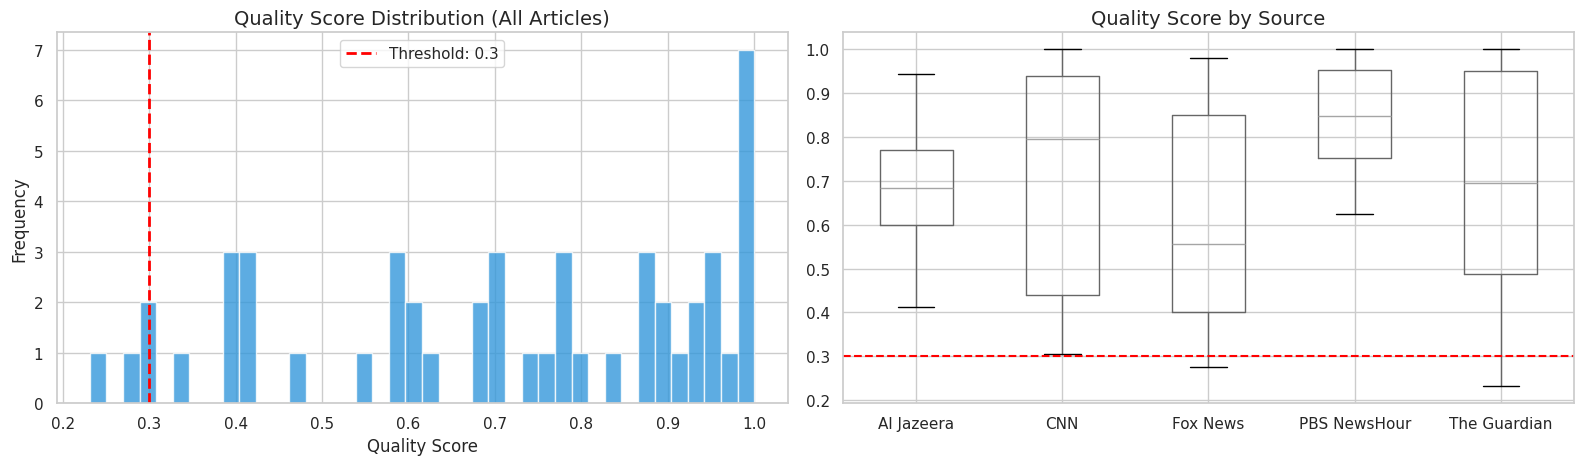


Dropping 3 articles below quality threshold 0.3:
source
Fox News        2
The Guardian    1

After quality filtering: 47 articles (dropped 3)


In [18]:
# ============================================================
# Quality Score Analysis & Filtering
# ============================================================

print("Quality Score Distribution:")
print(df["quality_score"].describe().to_string())
print()

# Distribution by source
print("Quality Score by Source:")
print(df.groupby("source")["quality_score"].describe().round(2).to_string())
print()

# Visualize quality score distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# a — Overall distribution
axes[0].hist(df["quality_score"].dropna(), bins=40, color="#3498db", edgecolor="white", alpha=0.8)
axes[0].axvline(QUALITY_THRESHOLD, color="red", ls="--", lw=2,
                label=f"Threshold: {QUALITY_THRESHOLD}")
axes[0].set_title("Quality Score Distribution (All Articles)")
axes[0].set_xlabel("Quality Score")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# b — By source (boxplot)
df.boxplot(column="quality_score", by="source", ax=axes[1],
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].axhline(QUALITY_THRESHOLD, color="red", ls="--", lw=1.5)
axes[1].set_title("Quality Score by Source")
axes[1].set_xlabel("")
plt.suptitle("")  # suppress default title from boxplot
plt.tight_layout()
plt.show()

# Apply quality filter
n_before = len(df)
low_quality_mask = df["quality_score"] < QUALITY_THRESHOLD
n_dropped = low_quality_mask.sum()

if n_dropped > 0:
    print(f"\nDropping {n_dropped:,} articles below quality threshold {QUALITY_THRESHOLD}:")
    print(df[low_quality_mask].groupby("source").size().to_string())
    df = df[~low_quality_mask].reset_index(drop=True)
    print(f"\nAfter quality filtering: {len(df):,} articles (dropped {n_dropped:,})")
else:
    print(f"\nNo articles below quality threshold {QUALITY_THRESHOLD}. All {len(df):,} retained.")

In [19]:
# ============================================================
# Sentiment Analysis -- Transformer (Chunked RoBERTa-large)
# ============================================================
# Model: j-hartmann/sentiment-roberta-large-english-3-classes
# Trained on 5 diverse datasets: SST, DynaSent, tweet_eval, emotion, Amazon reviews
# 3-class output: positive / neutral / negative
# Reference: Hartmann et al. (2023)

print(f"Loading sentiment model: {SENTIMENT_MODEL}")
sentiment_pipe = hf_pipeline(
    "sentiment-analysis",
    model=SENTIMENT_MODEL,
    tokenizer=SENTIMENT_MODEL,
    device=DEVICE,
    top_k=None,
)

# Access the tokenizer for proper chunk splitting
_sent_tokenizer = sentiment_pipe.tokenizer

# Normalise labels to lowercase (the model may output "Positive", "Neutral", "Negative")
_LABEL_NORM = {
    "positive": "positive", "Positive": "positive", "POSITIVE": "positive",
    "negative": "negative", "Negative": "negative", "NEGATIVE": "negative",
    "neutral": "neutral",  "Neutral": "neutral",  "NEUTRAL": "neutral",
}

def _normalize_label(label: str) -> str:
    return _LABEL_NORM.get(label, label.lower())


def _chunk_text(text: str, max_tokens: int = CHUNK_MAX_TOKENS,
                overlap: int = CHUNK_OVERLAP) -> list[str]:
    """Split text into overlapping token-based chunks, decoded back to strings."""
    if not text:
        return [text]
    token_ids = _sent_tokenizer.encode(text, add_special_tokens=False)
    if len(token_ids) <= max_tokens:
        return [text]
    chunks = []
    start = 0
    while start < len(token_ids):
        end = min(start + max_tokens, len(token_ids))
        chunk_ids = token_ids[start:end]
        chunk_text = _sent_tokenizer.decode(chunk_ids, skip_special_tokens=True)
        chunks.append(chunk_text)
        if end >= len(token_ids):
            break
        start += max_tokens - overlap
    return chunks


def _aggregate_chunk_scores(chunk_results: list[list[dict]]) -> dict:
    """Weighted-average chunk-level sentiment into a single article score.

    Each chunk gets weight = 1 (equal weighting across chunks).
    Returns {label, score, compound} where compound = P(pos) - P(neg).
    """
    total_pos, total_neg, total_neu = 0.0, 0.0, 0.0
    n_chunks = len(chunk_results)
    if n_chunks == 0:
        return {"label": "neutral", "score": 0.0, "compound": 0.0}
    for result in chunk_results:
        score_map = {_normalize_label(item["label"]): item["score"] for item in result}
        total_pos += score_map.get("positive", 0.0)
        total_neg += score_map.get("negative", 0.0)
        total_neu += score_map.get("neutral", 0.0)
    avg_pos = total_pos / n_chunks
    avg_neg = total_neg / n_chunks
    avg_neu = total_neu / n_chunks
    scores = {"positive": avg_pos, "negative": avg_neg, "neutral": avg_neu}
    best_label = max(scores, key=scores.get)
    return {
        "label": best_label,
        "score": scores[best_label],
        "compound": avg_pos - avg_neg,
    }


def _run_chunked_sentiment(texts: list[str], batch_size: int = BATCH_SENTIMENT) -> list[dict]:
    """Run sentiment on a list of texts, chunking long ones."""
    # Build flat list of all chunks + track which article they belong to
    all_chunks = []
    article_indices = []     # maps each chunk back to its article index
    for i, text in enumerate(texts):
        chunks = _chunk_text(text)
        for chunk in chunks:
            all_chunks.append(chunk)
            article_indices.append(i)

    n_articles = len(texts)
    print(f"  {len(all_chunks)} total chunks from {n_articles} articles "
          f"(avg {len(all_chunks)/max(n_articles,1):.1f} chunks/article)")

    # Run sentiment in batches on the flat chunk list
    all_results = []
    for j in tqdm(range(0, len(all_chunks), batch_size), desc="Chunked sentiment"):
        batch = all_chunks[j : j + batch_size]
        results = sentiment_pipe(batch, truncation=True, max_length=512)
        all_results.extend(results)

    # Group chunk results by article and aggregate
    article_chunk_results = defaultdict(list)
    for idx, result in zip(article_indices, all_results):
        article_chunk_results[idx].append(result)

    aggregated = []
    for i in range(n_articles):
        agg = _aggregate_chunk_scores(article_chunk_results.get(i, []))
        aggregated.append(agg)
    return aggregated


# Title (short text, no chunking needed)
print("Transformer sentiment on titles ...")
title_results_raw = []
title_texts = df["clean_title"].tolist()
for j in tqdm(range(0, len(title_texts), BATCH_SENTIMENT), desc="Title sentiment"):
    batch = title_texts[j : j + BATCH_SENTIMENT]
    results = sentiment_pipe(batch, truncation=True, max_length=512)
    title_results_raw.extend(results)

df["trans_title_label"] = [
    _normalize_label(max(r, key=lambda x: x["score"])["label"])
    for r in title_results_raw
]
df["trans_title_score"] = [max(r, key=lambda x: x["score"])["score"] for r in title_results_raw]
df["trans_title_compound"] = [
    {_normalize_label(item["label"]): item["score"] for item in r}.get("positive", 0)
    - {_normalize_label(item["label"]): item["score"] for item in r}.get("negative", 0)
    for r in title_results_raw
]

# Content (long text, use chunked approach)
print("Transformer sentiment on content (chunked) ...")
content_agg = _run_chunked_sentiment(df["clean_content"].tolist())
df["trans_content_label"]    = [a["label"]    for a in content_agg]
df["trans_content_score"]    = [a["score"]    for a in content_agg]
df["trans_content_compound"] = [a["compound"] for a in content_agg]

# Free GPU memory
del sentiment_pipe, _sent_tokenizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nTransformer title sentiment:")
print(df["trans_title_label"].value_counts().to_string())
print("\nTransformer content sentiment:")
print(df["trans_content_label"].value_counts().to_string())

Loading sentiment model: j-hartmann/sentiment-roberta-large-english-3-classes


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: j-hartmann/sentiment-roberta-large-english-3-classes
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Transformer sentiment on titles ...


Title sentiment:   0%|          | 0/2 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (605 > 512). Running this sequence through the model will result in indexing errors


Transformer sentiment on content (chunked) ...
  161 total chunks from 47 articles (avg 3.4 chunks/article)


Chunked sentiment:   0%|          | 0/6 [00:00<?, ?it/s]


Transformer title sentiment:
trans_title_label
neutral     38
negative     8
positive     1

Transformer content sentiment:
trans_content_label
neutral     34
negative    12
positive     1


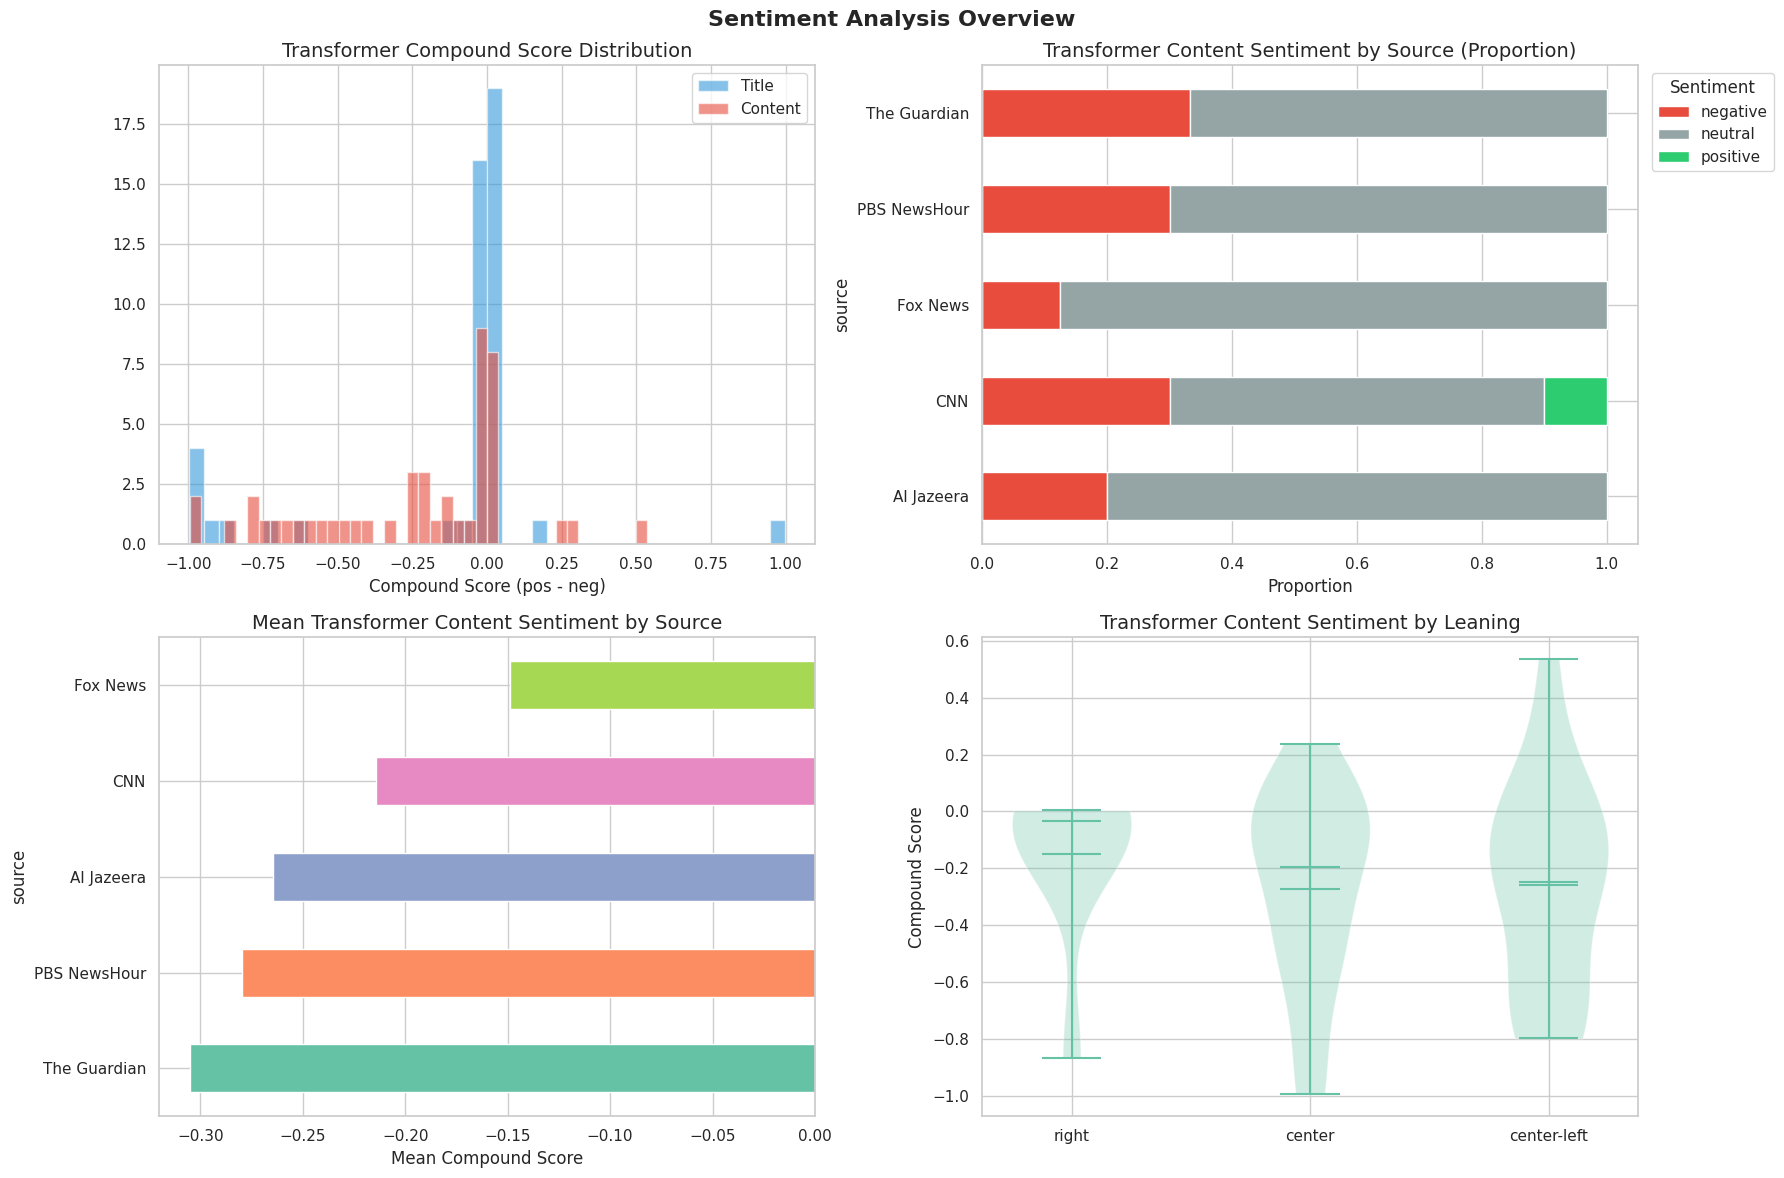

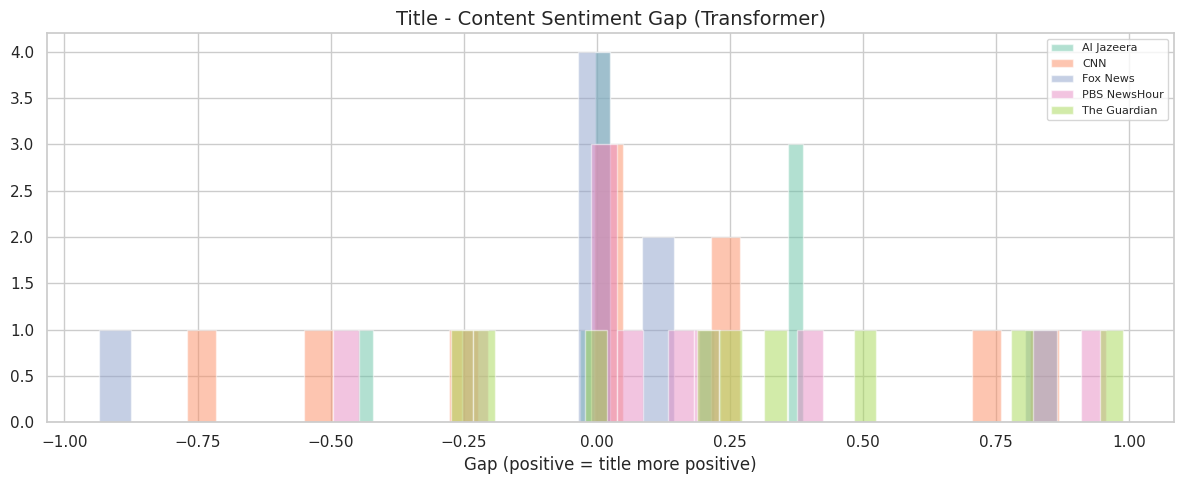

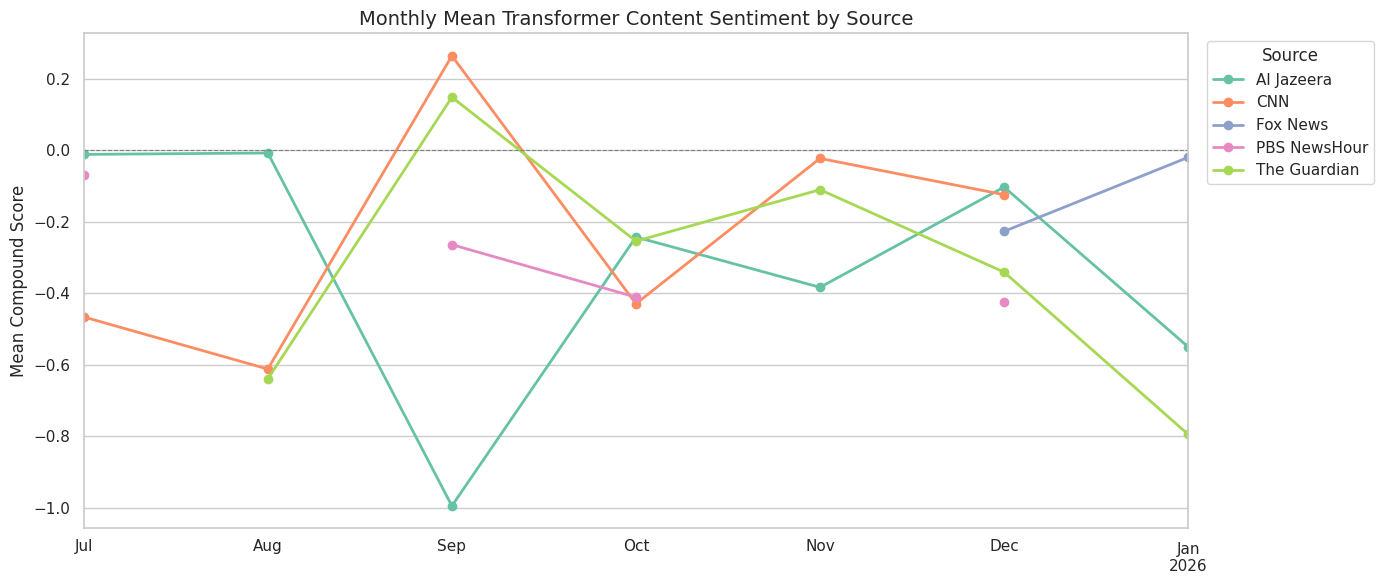

In [20]:
# ============================================================
# Sentiment Visualizations
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# a — Transformer compound distribution (title vs content)
axes[0, 0].hist(df["trans_title_compound"], bins=40, alpha=0.6, label="Title", color="#3498db")
axes[0, 0].hist(df["trans_content_compound"], bins=40, alpha=0.6, label="Content", color="#e74c3c")
axes[0, 0].set_title("Transformer Compound Score Distribution")
axes[0, 0].set_xlabel("Compound Score (pos - neg)")
axes[0, 0].legend()

# b — Transformer content sentiment label distribution by source
ct_sent = pd.crosstab(df["source"], df["trans_content_label"], normalize="index")
ct_sent.plot(
    kind="barh", stacked=True, ax=axes[0, 1],
    color={"negative": "#e74c3c", "neutral": "#95a5a6", "positive": "#2ecc71"},
)
axes[0, 1].set_title("Transformer Content Sentiment by Source (Proportion)")
axes[0, 1].set_xlabel("Proportion")
axes[0, 1].legend(title="Sentiment", bbox_to_anchor=(1.01, 1))

# c — Mean sentiment by source (Transformer content)
source_sent_t = df.groupby("source")["trans_content_compound"].mean().sort_values()
source_sent_t.plot(kind="barh", ax=axes[1, 0], color=sns.color_palette("Set2", len(source_sent_t)))
axes[1, 0].set_title("Mean Transformer Content Sentiment by Source")
axes[1, 0].set_xlabel("Mean Compound Score")

# d — Sentiment by political leaning (Transformer content)
leaning_order = ["right", "center", "center-left"]
leaning_data = [df[df["leaning"] == l]["trans_content_compound"].values
                for l in leaning_order if l in df["leaning"].values]
leaning_labels = [l for l in leaning_order if l in df["leaning"].values]
if leaning_data:
    parts = axes[1, 1].violinplot(leaning_data, showmeans=True, showmedians=True)
    axes[1, 1].set_xticks(range(1, len(leaning_labels) + 1))
    axes[1, 1].set_xticklabels(leaning_labels)
axes[1, 1].set_title("Transformer Content Sentiment by Leaning")
axes[1, 1].set_ylabel("Compound Score")

plt.suptitle("Sentiment Analysis Overview", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Title vs Content Sentiment gap
fig, ax = plt.subplots(figsize=(12, 5))
df["trans_gap"] = df["trans_title_compound"] - df["trans_content_compound"]

for src in df["source"].unique():
    subset = df[df["source"] == src]
    ax.hist(subset["trans_gap"], bins=30, alpha=0.5, label=src)
ax.set_title("Title - Content Sentiment Gap (Transformer)")
ax.set_xlabel("Gap (positive = title more positive)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Temporal sentiment trend
if not TEST_MODE or df["pub_month"].nunique() > 1:
    monthly_sent = df.groupby(["pub_month", "source"])["trans_content_compound"].mean().unstack()
    fig, ax = plt.subplots(figsize=(14, 6))
    monthly_sent.plot(ax=ax, marker="o", linewidth=2)
    ax.set_title("Monthly Mean Transformer Content Sentiment by Source")
    ax.set_ylabel("Mean Compound Score")
    ax.set_xlabel("")
    ax.legend(title="Source", bbox_to_anchor=(1.01, 1))
    ax.axhline(0, color="grey", ls="--", lw=0.8)
    plt.tight_layout()
    plt.show()

In [21]:
# ============================================================
# Zero-Shot Topic / Category Classification
# ============================================================

print(f"Loading zero-shot model: {ZS_MODEL}")
zs_pipe = hf_pipeline(
    "zero-shot-classification",
    model=ZS_MODEL,
    device=DEVICE,
)

_zs_tokenizer = zs_pipe.tokenizer

def _chunk_text_zs(text: str, max_tokens: int = ZS_CHUNK_MAX_TOKENS,
                   overlap: int = ZS_CHUNK_OVERLAP) -> list[str]:
    """Split text into overlapping token-based chunks for zero-shot classification.

    round-trip verification. The encode->decode->encode cycle can
    expand token count by up to ~29% due to boundary effects and whitespace
    normalization. We verify each chunk stays within the model's 1024 limit
    after accounting for hypothesis tokens (~30), and shrink if needed.
    """
    if not text:
        return [text]
    token_ids = _zs_tokenizer.encode(text, add_special_tokens=False)
    if len(token_ids) <= max_tokens:
        return [text]
    chunks = []
    start = 0
    while start < len(token_ids):
        end = min(start + max_tokens, len(token_ids))
        chunk_ids = token_ids[start:end]
        chunk_text = _zs_tokenizer.decode(chunk_ids, skip_special_tokens=True)

        # Round-trip verification: re-encode and check actual token count
        # BART-MNLI has 1024 max; hypothesis template adds ~30 tokens
        MAX_PREMISE_TOKENS = 990  # 1024 - ~30 for hypothesis - small buffer
        rt_ids = _zs_tokenizer.encode(chunk_text, add_special_tokens=False)
        if len(rt_ids) > MAX_PREMISE_TOKENS:
            # Trim the round-tripped tokens and re-decode
            rt_ids = rt_ids[:MAX_PREMISE_TOKENS]
            chunk_text = _zs_tokenizer.decode(rt_ids, skip_special_tokens=True)

        chunks.append(chunk_text)
        if end >= len(token_ids):
            break
        start += max_tokens - overlap
    return chunks


def _aggregate_zs_chunk_results(chunk_results: list[dict],
                                categories: list[str]) -> dict:
    """Average zero-shot scores across chunks, return top labels + scores.

    Each chunk produces a dict with 'labels' and 'scores'. We average the
    score for each category across all chunks and re-rank.
    """
    n = len(chunk_results)
    if n == 0:
        return {"labels": categories, "scores": [0.0] * len(categories)}

    # Accumulate scores per category
    score_sums = defaultdict(float)
    for result in chunk_results:
        for label, score in zip(result["labels"], result["scores"]):
            score_sums[label] += score

    # Average and sort
    avg_scores = {cat: score_sums.get(cat, 0.0) / n for cat in categories}
    sorted_cats = sorted(avg_scores.keys(), key=lambda c: avg_scores[c], reverse=True)
    return {
        "labels": sorted_cats,
        "scores": [avg_scores[c] for c in sorted_cats],
    }


# Build (title + full content) input for each article
# Title goes first for context, then full cleaned content
zs_inputs = (df["clean_title"] + ". " + df["clean_content"]).tolist()

# Chunk all articles
all_chunks = []       # flat list of text chunks
article_indices = []  # maps each chunk -> article index
n_chunks_per = []     # number of chunks per article

for i, text in enumerate(zs_inputs):
    chunks = _chunk_text_zs(text)
    n_chunks_per.append(len(chunks))
    for chunk in chunks:
        all_chunks.append(chunk)
        article_indices.append(i)

print(f"Running zero-shot classification ({len(CANDIDATE_CATEGORIES)} categories) ...")
print(f"  {len(all_chunks)} total chunks from {len(df)} articles "
      f"(avg {len(all_chunks)/max(len(df),1):.1f} chunks/article)")

# Run zero-shot on all chunks in batches
all_chunk_results = []
for j in tqdm(range(0, len(all_chunks), BATCH_ZS), desc="Zero-shot (chunked)"):
    batch = all_chunks[j : j + BATCH_ZS]
    batch_out = zs_pipe(
        batch,
        CANDIDATE_CATEGORIES,
        multi_label=True,
        hypothesis_template="This news article is about {}.",
    )
    if isinstance(batch_out, dict):
        batch_out = [batch_out]
    all_chunk_results.extend(batch_out)

# Aggregate chunk results back to article level
zs_results = []
chunk_idx = 0
for i in range(len(df)):
    n_ch = n_chunks_per[i]
    article_chunk_results = all_chunk_results[chunk_idx : chunk_idx + n_ch]
    chunk_idx += n_ch
    agg = _aggregate_zs_chunk_results(article_chunk_results, CANDIDATE_CATEGORIES)
    zs_results.append(agg)

df["category"]       = [r["labels"][0]  for r in zs_results]
df["category_score"] = [r["scores"][0]  for r in zs_results]
df["category_top3"]  = [r["labels"][:3] for r in zs_results]

# Store all category scores for richer analysis
df["category_all_scores"] = [
    dict(zip(r["labels"], r["scores"])) for r in zs_results
]

# Free GPU memory
del zs_pipe, _zs_tokenizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nCategory distribution:")
print(df["category"].value_counts().to_string())
print(f"\nMean classification confidence: {df['category_score'].mean():.3f}")

# Flag low-confidence classifications
low_conf = (df["category_score"] < 0.4).sum()
print(f"Low confidence (<0.4) articles: {low_conf}/{len(df)} "
      f"({low_conf/len(df)*100:.1f}%)")

# Show mean confidence by source
print("\nMean confidence by source:")
print(df.groupby("source")["category_score"].mean().sort_values(ascending=False).to_string())

Loading zero-shot model: facebook/bart-large-mnli


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (1034 > 1024). Running this sequence through the model will result in indexing errors


Running zero-shot classification (11 categories) ...
  114 total chunks from 47 articles (avg 2.4 chunks/article)


Zero-shot (chunked):   0%|          | 0/15 [00:00<?, ?it/s]


Category distribution:
category
Politics & Government                7
International Affairs & Diplomacy    7
Military & Defense                   6
Entertainment & Culture              5
Science & Technology                 5
Environment & Climate                4
Business & Economy                   4
Sports                               4
Crime & Justice                      3
Health & Medicine                    2

Mean classification confidence: 0.890
Low confidence (<0.4) articles: 0/47 (0.0%)

Mean confidence by source:
source
CNN             0.918022
Al Jazeera      0.914884
PBS NewsHour    0.891574
Fox News        0.878823
The Guardian    0.838390


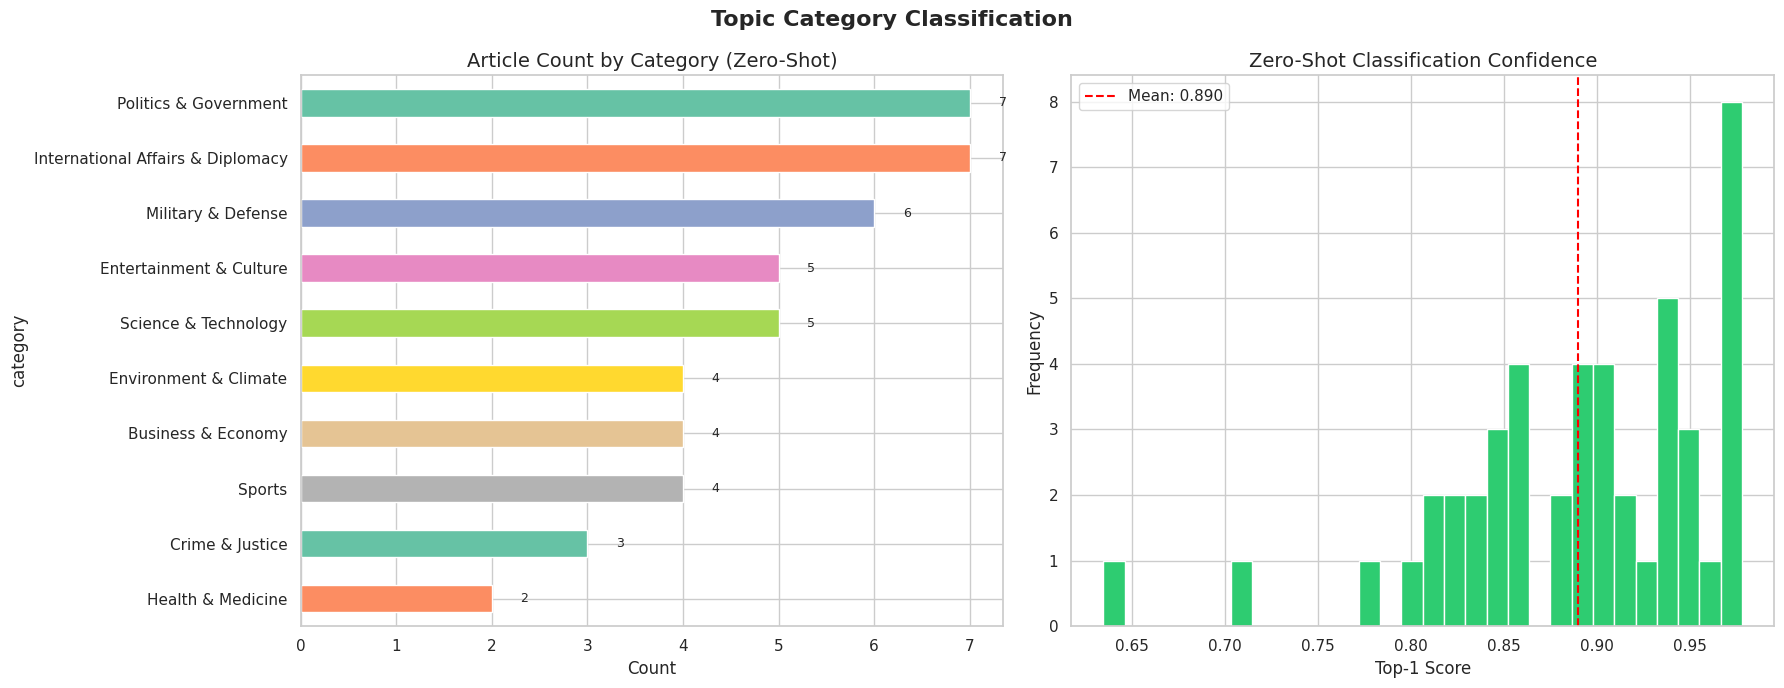

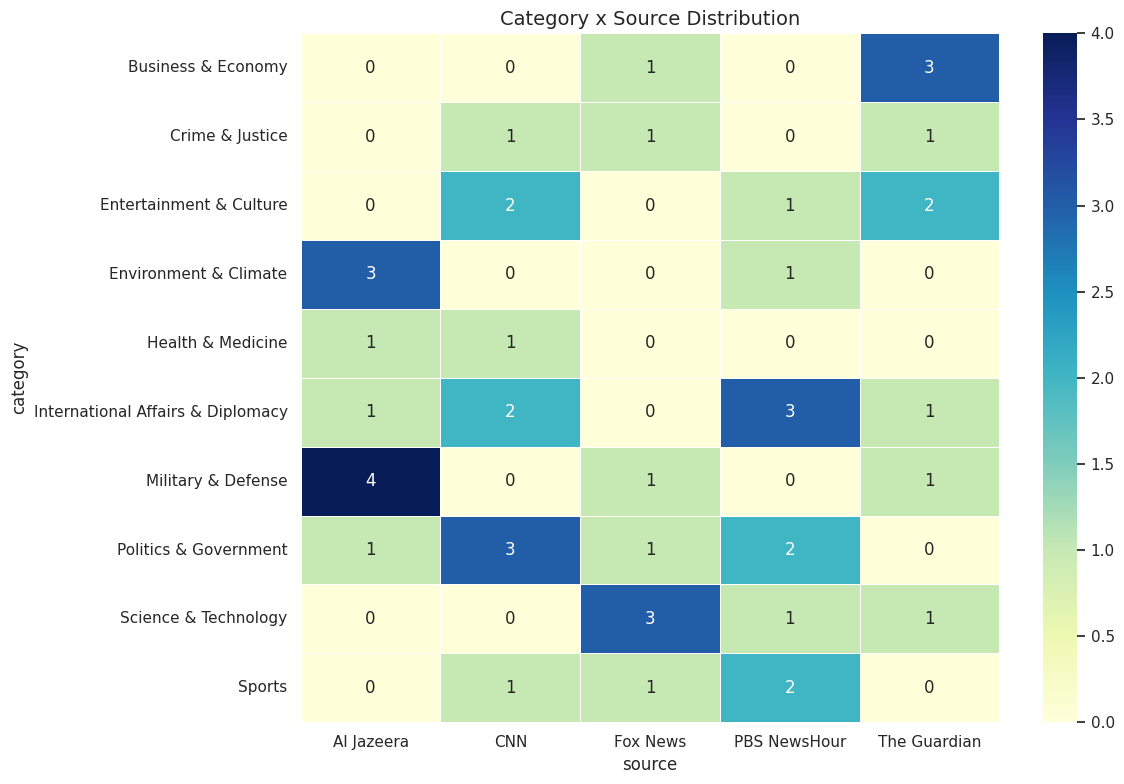

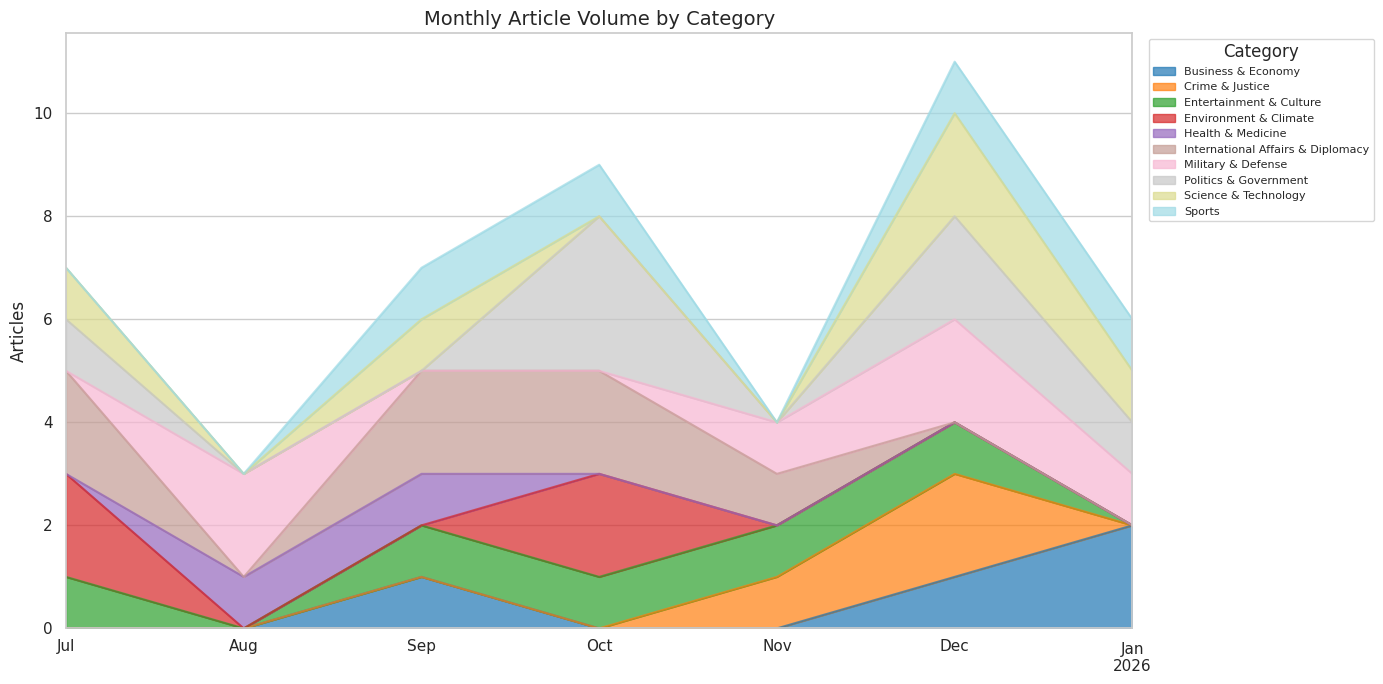

In [22]:
# ============================================================
# Category Visualizations
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# a — Overall category distribution
cat_counts = df["category"].value_counts()
cat_counts.plot(kind="barh", ax=axes[0], color=sns.color_palette("Set2", len(cat_counts)))
axes[0].set_title("Article Count by Category (Zero-Shot)")
axes[0].set_xlabel("Count")
axes[0].invert_yaxis()
for i, (v, name) in enumerate(zip(cat_counts.values, cat_counts.index)):
    axes[0].text(v + 0.3, i, str(v), va="center", fontsize=9)

# b — Classification confidence distribution
axes[1].hist(df["category_score"], bins=30, color="#2ecc71", edgecolor="white")
axes[1].set_title("Zero-Shot Classification Confidence")
axes[1].set_xlabel("Top-1 Score")
axes[1].set_ylabel("Frequency")
axes[1].axvline(df["category_score"].mean(), color="red", ls="--",
                label=f'Mean: {df["category_score"].mean():.3f}')
axes[1].legend()

plt.suptitle("Topic Category Classification", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# c — Category x Source heatmap
ct = pd.crosstab(df["category"], df["source"])
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu", ax=ax, linewidths=0.5)
ax.set_title("Category x Source Distribution")
plt.tight_layout()
plt.show()

# d — Temporal category trend
if not TEST_MODE or df["pub_month"].nunique() > 1:
    monthly_cat = df.groupby(["pub_month", "category"]).size().unstack(fill_value=0)
    fig, ax = plt.subplots(figsize=(14, 7))
    monthly_cat.plot.area(ax=ax, alpha=0.7, colormap="tab20")
    ax.set_title("Monthly Article Volume by Category")
    ax.set_ylabel("Articles")
    ax.set_xlabel("")
    ax.legend(title="Category", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.tight_layout()
    plt.show()

In [23]:
# ============================================================
# Named Entity Recognition (spaCy -- Batched)
# ============================================================
# Also extracts person-sentence pairs for sentence-level
# sentiment analysis later

print(f"Loading spaCy model: {SPACY_MODEL}")
nlp = spacy.load(SPACY_MODEL)
nlp.max_length = 80_000

ENTITY_TYPES = ("PERSON", "ORG", "GPE")

def _extract_entities_from_doc(doc) -> dict:
    """Extract entities from a spaCy Doc object."""
    entities = defaultdict(list)
    for ent in doc.ents:
        if ent.label_ in ENTITY_TYPES:
            name = ent.text.strip()
            # Remove trailing possessives
            name = re.sub(r"['\u2019\u2018]s$", "", name)
            # Remove leading titles/honorifics for consistency
            name = re.sub(r"^(Mr\.?|Mrs\.?|Ms\.?|Dr\.?|Prof\.?|Sen\.?|Rep\.?|Gov\.?|Pres\.?)\s+",
                          "", name)
            if len(name) > 1:
                entities[ent.label_].append(name)
    return dict(entities)


def _extract_person_sentences(doc) -> list[dict]:
    """Extract (person_name, sentence_text) pairs from a spaCy Doc.

    Uses ent.sent to get the sentence containing each PERSON entity.
    Returns a list of dicts: [{"raw_name": ..., "sentence": ...}, ...]
    """
    pairs = []
    for ent in doc.ents:
        if ent.label_ != "PERSON":
            continue
        name = ent.text.strip()
        name = re.sub(r"['\u2019\u2018]s$", "", name)
        name = re.sub(r"^(Mr\.?|Mrs\.?|Ms\.?|Dr\.?|Prof\.?|Sen\.?|Rep\.?|Gov\.?|Pres\.?)\s+",
                      "", name)
        if len(name) <= 1:
            continue
        sent_text = ent.sent.text.strip() if ent.sent else ""
        if sent_text:
            pairs.append({"raw_name": name, "sentence": sent_text})
    return pairs


print(f"Running NER on {len(df)} articles (batched) ...")
texts = df["clean_content"].tolist()

# Use nlp.pipe for efficient batched processing
ner_results = []
person_sentence_data = []  # global list of person-sentence pairs

for doc_idx, doc in enumerate(tqdm(nlp.pipe(texts, batch_size=BATCH_NER),
                                    total=len(texts), desc="NER (batched)")):
    ner_results.append(_extract_entities_from_doc(doc))

    # Extract person-sentence pairs for this article
    pairs = _extract_person_sentences(doc)
    for pair in pairs:
        pair["article_idx"] = doc_idx
    person_sentence_data.extend(pairs)

df["persons"]       = [r.get("PERSON", []) for r in ner_results]
df["organizations"] = [r.get("ORG", [])    for r in ner_results]
df["locations"]     = [r.get("GPE", [])    for r in ner_results]

df["n_persons"] = df["persons"].apply(len)
df["n_orgs"]    = df["organizations"].apply(len)
df["n_locs"]    = df["locations"].apply(len)

print(f"\nTotal PERSON mentions : {df['n_persons'].sum():,}")
print(f"Total ORG mentions    : {df['n_orgs'].sum():,}")
print(f"Total GPE mentions    : {df['n_locs'].sum():,}")

# Build person-sentence DataFrame for later use
person_sentences_df = pd.DataFrame(person_sentence_data)
if len(person_sentences_df) > 0:
    print(f"\nPerson-sentence pairs extracted: {len(person_sentences_df):,}")
    print(f"Unique sentences: {person_sentences_df['sentence'].nunique():,}")
else:
    print("\nNo person-sentence pairs extracted.")

Loading spaCy model: en_core_web_trf
Running NER on 47 articles (batched) ...


NER (batched):   0%|          | 0/47 [00:00<?, ?it/s]


Total PERSON mentions : 892
Total ORG mentions    : 638
Total GPE mentions    : 716

Person-sentence pairs extracted: 892
Unique sentences: 617


Resolving person names (two-phase approach) ...
  Raw unique names: 420
  Resolved unique names: 330
  Reduction: 90 variants merged
  Excluded 48 unresolved single-word names from rankings
  Display-eligible persons: 282

Top 30 Named Persons:
   1. Donald Trump                      101 mentions  (5 sources)
   2. Carlos Alcaraz                     25 mentions  (1 sources)
   3. Aftyn Behn                         22 mentions  (2 sources)
   4. Jannik Sinner                      21 mentions  (1 sources)
   5. Joe Biden                          17 mentions  (3 sources)
   6. Elon Musk                          15 mentions  (2 sources)
   7. Van Epps                           14 mentions  (2 sources)
   8. William Brangham                   13 mentions  (1 sources)
   9. Benjamin Netanyahu                 12 mentions  (1 sources)
  10. Abigail Spanberger                 11 mentions  (2 sources)
  11. Volodymyr Zelenskyy                11 mentions  (2 sources)
  12. Shohei Ohtani          

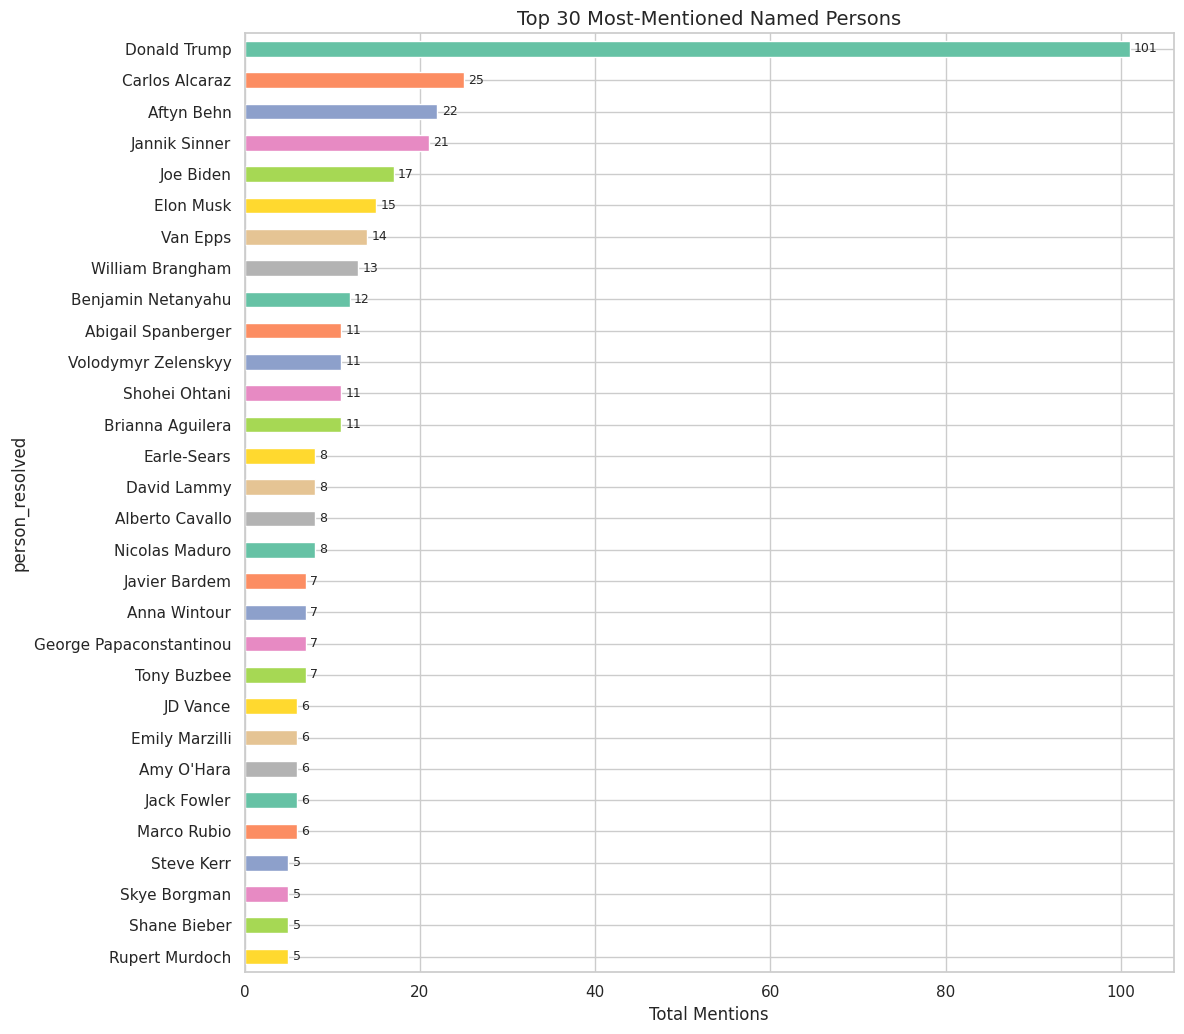

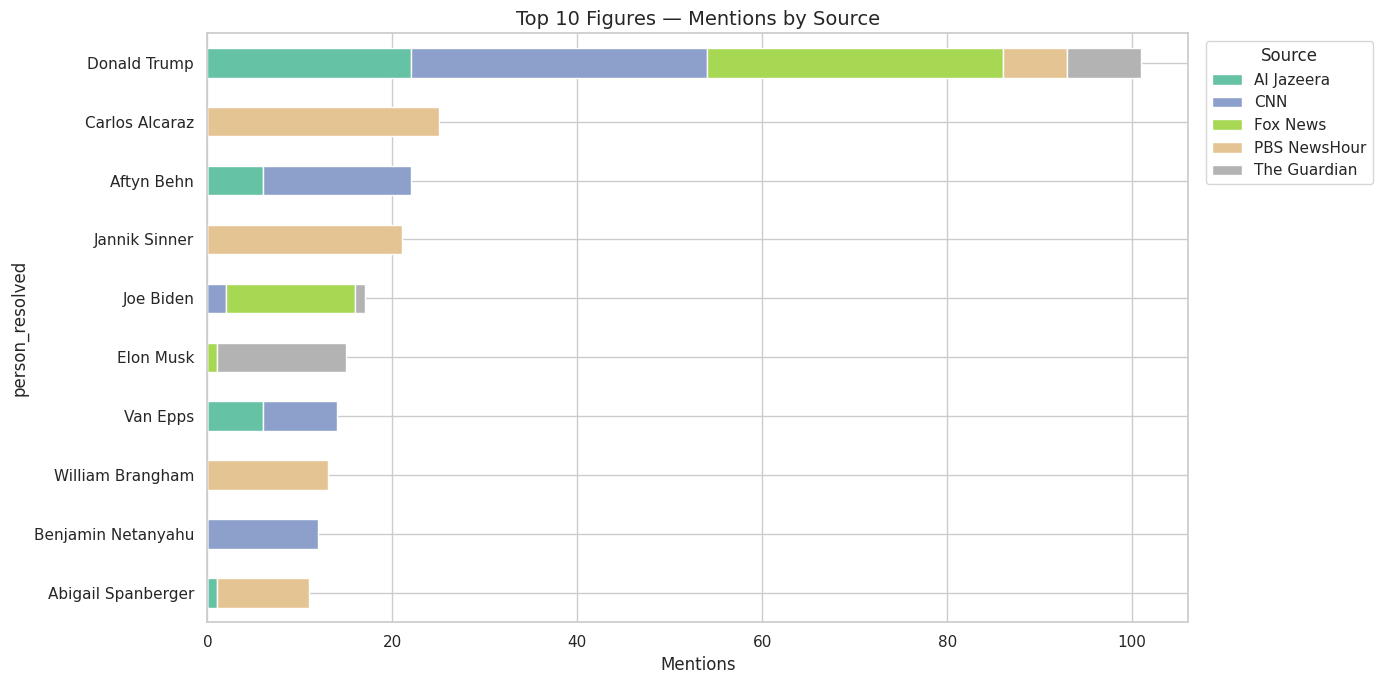

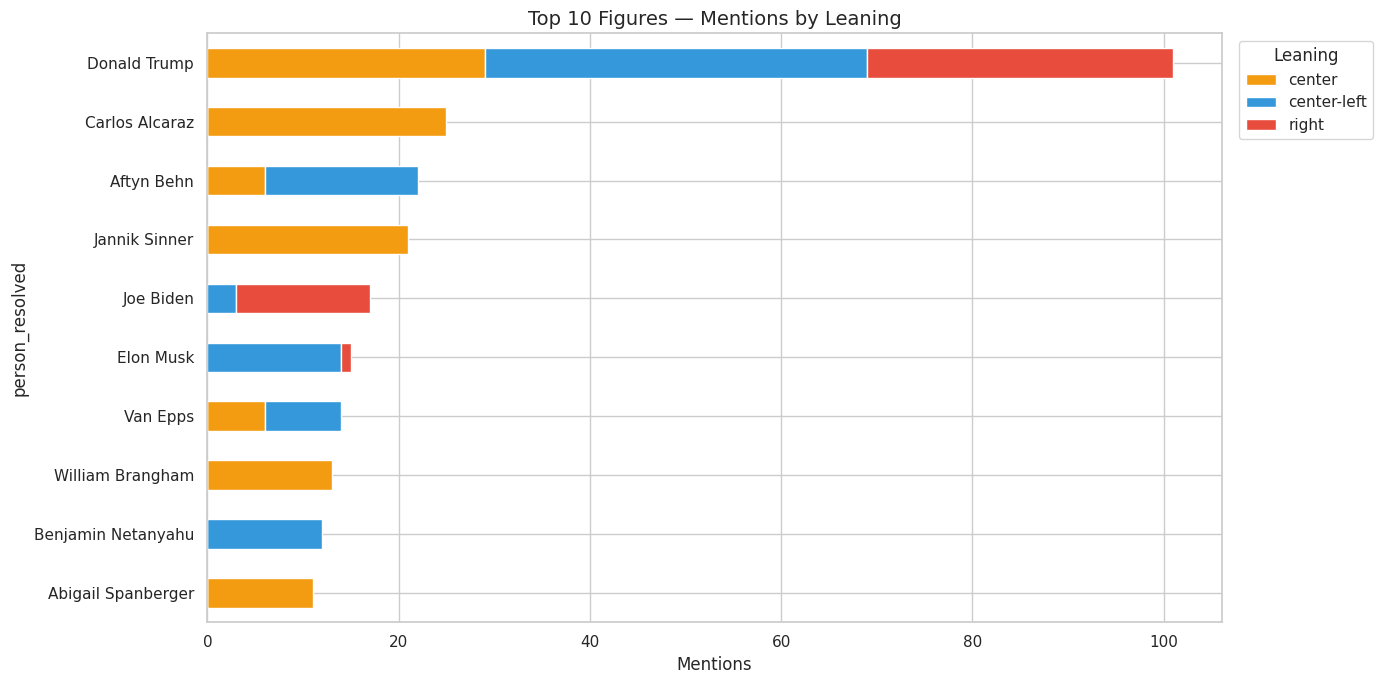

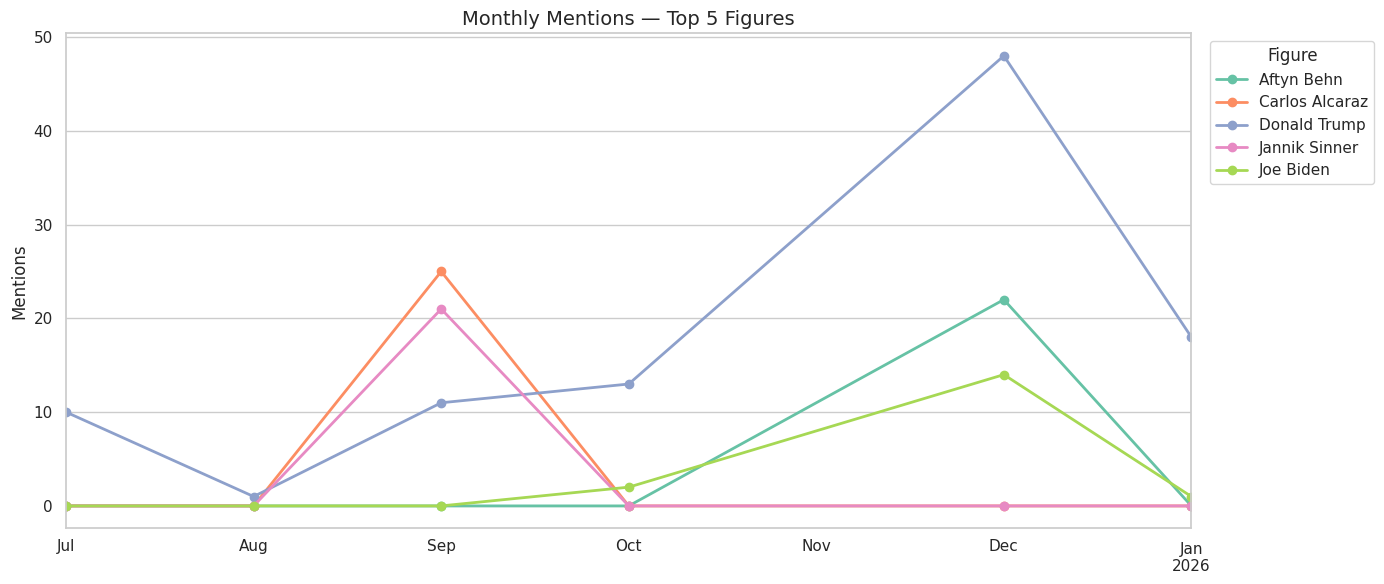

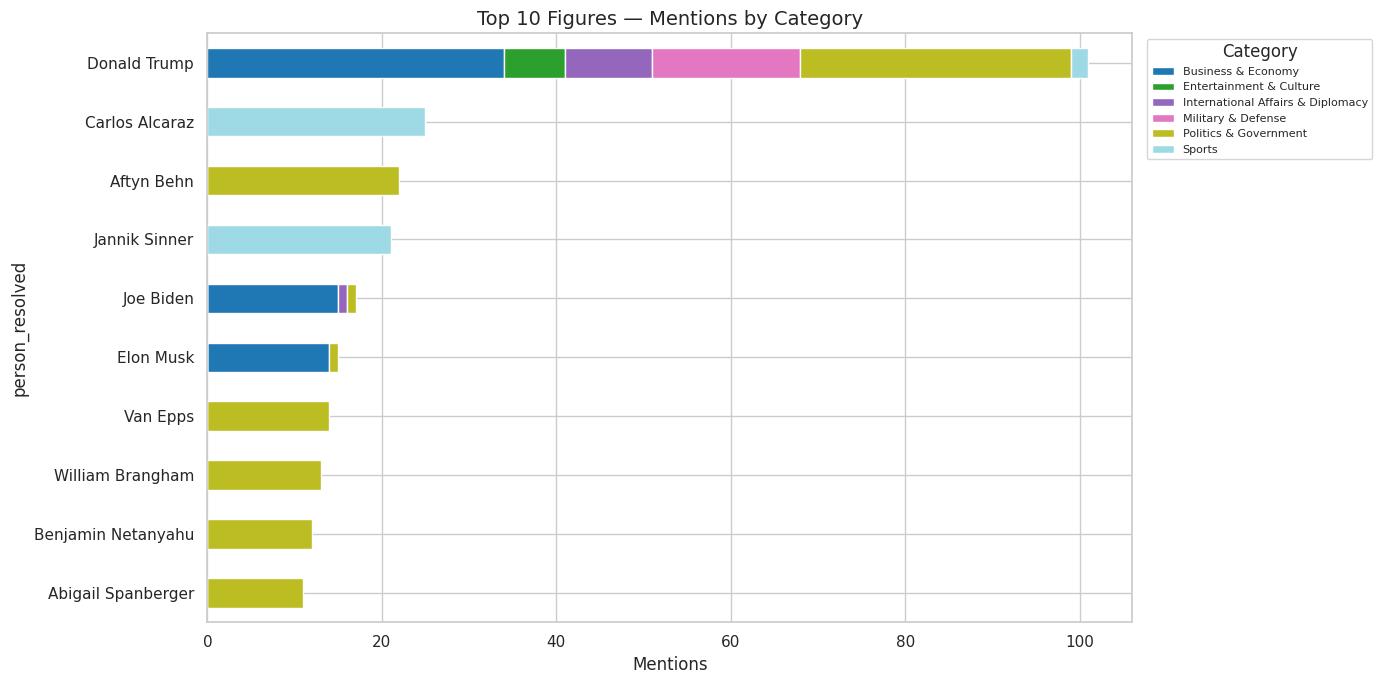

In [24]:
# ==========================================================================
# Named Persons — Name Resolution & Visualizations
# ==========================================================================

# Tunable parameters
FUZZY_NAME_THRESHOLD  = 85   # min token_sort_ratio to merge two full names
FUZZY_TOKEN_THRESHOLD = 85   # min fuzz.ratio for last-token cross-bucket blocking
MIN_TOKEN_LEN_CROSS   = 3   # skip cross-bucket on very short last-tokens
MIN_FREQ_CROSS_BUCKET = 2   # only cross-match names with >= N mentions
TOP_N_FIGURES         = 30   # main bar chart size
TOP_N_DETAIL          = 10   # source / leaning breakdowns
TOP_N_TEMPORAL        = 5    # temporal trend plot
SINGLE_TOKEN_AMBIGUITY_RATIO = 3.0  # Phase 2: top match must have >= 3x the
                                     # frequency of 2nd match to auto-assign
MIN_DISPLAY_NAME_TOKENS = 2   # >>> PEER-REVIEW: exclude unresolved single-word
                              # names (e.g. "Green", "Brown") from top-N displays
                              # to prevent ambiguous entities contaminating results

# -- Helpers -------------------------------------------------------------------
def _tokenize_name(name: str) -> list:
    """Lowercase, split on whitespace / hyphens, strip trailing periods."""
    tokens = re.split(r"[\s\-]+", name.lower().strip())
    return [t.rstrip(".") for t in tokens if t.rstrip(".")]


class _UnionFind:
    """Weighted quick-union with iterative path compression."""

    def __init__(self):
        self._parent = {}
        self._rank = {}

    def find(self, x):
        if x not in self._parent:
            self._parent[x] = x
            self._rank[x] = 0
        root = x
        while self._parent[root] != root:
            root = self._parent[root]
        # path compression
        while self._parent[x] != root:
            self._parent[x], x = root, self._parent[x]
        return root

    def union(self, x, y):
        rx, ry = self.find(x), self.find(y)
        if rx == ry:
            return
        if self._rank[rx] < self._rank[ry]:
            rx, ry = ry, rx
        self._parent[ry] = rx
        if self._rank[rx] == self._rank[ry]:
            self._rank[rx] += 1


def _resolve_person_names(raw_freq: pd.Series,
                          fuzzy_name_thresh: int = FUZZY_NAME_THRESHOLD,
                          fuzzy_token_thresh: int = FUZZY_TOKEN_THRESHOLD,
                          min_token_len_cross: int = MIN_TOKEN_LEN_CROSS,
                          min_freq_cross: int = MIN_FREQ_CROSS_BUCKET,
                          ) -> dict:
    """
    Build a mapping  raw_name -> canonical_display_name.

    TWO-PHASE APPROACH:
      Phase 1: Cluster only multi-word names (>= 2 tokens) using:
        a. Token-suffix match — ["trump"] is a suffix of ["donald", "trump"]
           (ONLY among multi-word names)
        b. First-and-last token match — names sharing first & last tokens
        c. Fuzzy match — token_sort_ratio >= threshold
        d. Cross-bucket blocking for transliteration variants
      Phase 2: Assign single-word names to existing clusters:
        - Match single-word name to clusters whose canonical name's last
          token matches the single-word name.
        - Only assign if one cluster dominates (frequency ratio >= threshold).
        - Otherwise keep the single-word name as its own entity.
    """
    unique_names = raw_freq.index.tolist()
    tok_map = {n: _tokenize_name(n) for n in unique_names}

    # Separate multi-word and single-word names
    multi_word_names = [n for n in unique_names if len(tok_map[n]) >= 2]
    single_word_names = [n for n in unique_names if len(tok_map[n]) == 1]

    # -- PHASE 1: Cluster multi-word names only --

    uf = _UnionFind()

    # Index multi-word names by last token
    lt_idx = defaultdict(list)
    for name in multi_word_names:
        toks = tok_map[name]
        if toks:
            lt_idx[toks[-1]].append(name)

    # Within each last-token bucket: suffix, first+last, fuzzy
    for _lt, bucket in lt_idx.items():
        if len(bucket) < 2:
            continue
        for a, b in combinations(bucket, 2):
            ta, tb = tok_map[a], tok_map[b]
            # suffix match (only among multi-word — no single-token bridges)
            if _is_suffix(ta, tb) or _is_suffix(tb, ta):
                uf.union(a, b)
                continue
            # first-and-last token match
            if ta[0] == tb[0] and ta[-1] == tb[-1]:
                uf.union(a, b)
                continue
            # fuzzy
            if fuzz.token_sort_ratio(a, b) >= fuzzy_name_thresh:
                uf.union(a, b)

    # Cross-bucket blocking (only multi-word names)
    last_tokens = list(lt_idx.keys())
    for i, lt_a in enumerate(last_tokens):
        if len(lt_a) < min_token_len_cross:
            continue
        for lt_b in last_tokens[i + 1:]:
            if len(lt_b) < min_token_len_cross:
                continue
            if fuzz.ratio(lt_a, lt_b) < fuzzy_token_thresh:
                continue
            # Cross-check pairs between the two buckets
            cands_a = [n for n in lt_idx[lt_a] if raw_freq[n] >= min_freq_cross]
            cands_b = [n for n in lt_idx[lt_b] if raw_freq[n] >= min_freq_cross]
            for a in cands_a:
                for b in cands_b:
                    ta, tb = tok_map[a], tok_map[b]
                    if _is_suffix(ta, tb) or _is_suffix(tb, ta):
                        uf.union(a, b)
                    elif ta[0] == tb[0]:
                        if fuzz.token_sort_ratio(a, b) >= fuzzy_name_thresh:
                            uf.union(a, b)

    # Build multi-word clusters with canonical names (most frequent variant)
    mw_clusters = defaultdict(list)
    for name in multi_word_names:
        root = uf.find(name)
        mw_clusters[root].append(name)

    # Canonical = most frequent variant (prefer longest on tie)
    mw_canonical = {}
    for root, members in mw_clusters.items():
        best = max(members, key=lambda n: (raw_freq[n], len(n)))
        for m in members:
            mw_canonical[m] = best

    # -- PHASE 2: Assign single-word names to existing clusters --

    # Build a lookup: last_token -> list of (canonical_name, total_cluster_freq)
    canonical_by_last_token = defaultdict(list)
    for root, members in mw_clusters.items():
        canon = mw_canonical[root]
        cluster_freq = sum(raw_freq[m] for m in members)
        canon_last = tok_map[canon][-1] if tok_map[canon] else ""
        if canon_last:
            canonical_by_last_token[canon_last].append((canon, cluster_freq))

    sw_canonical = {}
    for name in single_word_names:
        tok = tok_map[name][0]  # the single token, lowercased
        candidates = canonical_by_last_token.get(tok, [])

        if len(candidates) == 0:
            # No matching multi-word cluster — keep as standalone
            sw_canonical[name] = name
        elif len(candidates) == 1:
            # Unambiguous — assign to the only matching cluster
            sw_canonical[name] = candidates[0][0]
        else:
            # Multiple candidates — only assign if top candidate dominates
            candidates_sorted = sorted(candidates, key=lambda x: x[1], reverse=True)
            top_freq = candidates_sorted[0][1]
            second_freq = candidates_sorted[1][1]
            if second_freq == 0 or (top_freq / max(second_freq, 1)) >= SINGLE_TOKEN_AMBIGUITY_RATIO:
                sw_canonical[name] = candidates_sorted[0][0]
            else:
                # Ambiguous — keep separate to avoid false merges
                sw_canonical[name] = name

    # Merge both mappings
    mapping = {}
    mapping.update(mw_canonical)
    mapping.update(sw_canonical)

    return mapping


def _is_suffix(short_toks: list, long_toks: list) -> bool:
    """True if short_toks is a strict suffix of long_toks."""
    if len(short_toks) >= len(long_toks):
        return False
    return long_toks[-len(short_toks):] == short_toks


# -- Build raw frequency from NER results --
print("Resolving person names (two-phase approach) ...")
all_persons = []
for idx, row in df.iterrows():
    for name in row["persons"]:
        all_persons.append({"article_idx": idx, "raw_name": name})

if len(all_persons) == 0:
    print("No person entities found. Skipping name resolution.")
    persons_df = pd.DataFrame()
    person_freq = pd.Series(dtype=int)
    name_map = {}
else:
    persons_raw = pd.DataFrame(all_persons)
    raw_freq = persons_raw["raw_name"].value_counts()
    print(f"  Raw unique names: {len(raw_freq):,}")

    name_map = _resolve_person_names(raw_freq)
    persons_raw["person_resolved"] = persons_raw["raw_name"].map(name_map)

    # Merge article metadata
    persons_df = persons_raw.merge(
        df[["source", "leaning", "pub_date", "pub_month",
            "trans_content_compound",
            "category"]],
        left_on="article_idx", right_index=True, how="left",
    )

    person_freq = persons_df["person_resolved"].value_counts()
    print(f"  Resolved unique names: {len(person_freq):,}")
    print(f"  Reduction: {len(raw_freq) - len(person_freq):,} variants merged")

    # >>> PEER-REVIEW: filter unresolved single-word names from rankings
    # In the full 56k-article corpus, single-word names like "Green", "Brown",
    # "Lee" accumulate hundreds of spurious mentions from unrelated contexts.
    # We keep them in persons_df for data completeness but exclude from
    # person_freq (used by all downstream top-N charts and analyses).
    person_freq_all = person_freq.copy()  # preserve unfiltered for saved data
    _display_mask = pd.Series(
        [len(_tokenize_name(n)) >= MIN_DISPLAY_NAME_TOKENS for n in person_freq.index],
        index=person_freq.index,
    )
    n_sw_filtered = (~_display_mask).sum()
    person_freq = person_freq[_display_mask]
    if n_sw_filtered > 0:
        print(f"  Excluded {n_sw_filtered} unresolved single-word names from rankings")
        print(f"  Display-eligible persons: {len(person_freq):,}")

    # Show top figures
    print(f"\nTop {TOP_N_FIGURES} Named Persons:")
    for i, (name, count) in enumerate(person_freq.head(TOP_N_FIGURES).items(), 1):
        n_sources = persons_df[persons_df["person_resolved"] == name]["source"].nunique()
        print(f"  {i:2d}. {name:<30s}  {count:>5,} mentions  ({n_sources} sources)")

    # -- Apply name_map to person_sentences_df --
    if len(person_sentences_df) > 0 and len(name_map) > 0:
        person_sentences_df["person_resolved"] = person_sentences_df["raw_name"].map(name_map)
        # Fill any unmapped names with the raw name
        person_sentences_df["person_resolved"] = person_sentences_df["person_resolved"].fillna(
            person_sentences_df["raw_name"]
        )
        # Merge article metadata
        person_sentences_df_enriched = person_sentences_df.merge(
            df[["source", "leaning", "pub_date", "pub_month"]],
            left_on="article_idx", right_index=True, how="left",
        )
        # Deduplicate: same person + same sentence in same article
        person_sentences_df_enriched = person_sentences_df_enriched.drop_duplicates(
            subset=["article_idx", "person_resolved", "sentence"]
        ).reset_index(drop=True)
        print(f"\nPerson-sentence pairs after name resolution: {len(person_sentences_df_enriched):,}")
        print(f"Unique resolved persons in sentences: {person_sentences_df_enriched['person_resolved'].nunique():,}")
    else:
        person_sentences_df_enriched = pd.DataFrame()

    # -- Visualizations (same as original but with resolved names) --

    # a — Top figures bar chart
    fig, ax = plt.subplots(figsize=(12, max(6, TOP_N_FIGURES * 0.35)))
    top = person_freq.head(TOP_N_FIGURES)
    top.plot(kind="barh", ax=ax, color=sns.color_palette("Set2", len(top)))
    ax.invert_yaxis()
    ax.set_xlabel("Total Mentions")
    ax.set_title(f"Top {TOP_N_FIGURES} Most-Mentioned Named Persons")
    for i, v in enumerate(top.values):
        ax.text(v + 0.5, i, f"{v:,}", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()

    # b — Top figures by source (stacked)
    top_detail = person_freq.head(TOP_N_DETAIL).index.tolist()
    detail_df = persons_df[persons_df["person_resolved"].isin(top_detail)]
    ct = pd.crosstab(detail_df["person_resolved"], detail_df["source"])
    ct = ct.loc[[f for f in top_detail if f in ct.index]]

    fig, ax = plt.subplots(figsize=(14, 7))
    ct.plot(kind="barh", stacked=True, ax=ax, colormap="Set2")
    ax.invert_yaxis()
    ax.set_xlabel("Mentions")
    ax.set_title(f"Top {TOP_N_DETAIL} Figures — Mentions by Source")
    ax.legend(title="Source", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

    # c — Top figures by leaning (stacked)
    ct_lean = pd.crosstab(detail_df["person_resolved"], detail_df["leaning"])
    ct_lean = ct_lean.loc[[f for f in top_detail if f in ct_lean.index]]

    fig, ax = plt.subplots(figsize=(14, 7))
    ct_lean.plot(kind="barh", stacked=True, ax=ax,
                 color={"right": "#e74c3c", "center": "#f39c12", "center-left": "#3498db"})
    ax.invert_yaxis()
    ax.set_xlabel("Mentions")
    ax.set_title(f"Top {TOP_N_DETAIL} Figures — Mentions by Leaning")
    ax.legend(title="Leaning", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

    # d — Temporal trend for top figures
    if not TEST_MODE or df["pub_month"].nunique() > 1:
        top_temporal = person_freq.head(TOP_N_TEMPORAL).index.tolist()
        temp_df = persons_df[persons_df["person_resolved"].isin(top_temporal)]
        monthly_fig = temp_df.groupby(["pub_month", "person_resolved"]).size().unstack(fill_value=0)

        fig, ax = plt.subplots(figsize=(14, 6))
        monthly_fig.plot(ax=ax, marker="o", linewidth=2)
        ax.set_title(f"Monthly Mentions — Top {TOP_N_TEMPORAL} Figures")
        ax.set_ylabel("Mentions")
        ax.set_xlabel("")
        ax.legend(title="Figure", bbox_to_anchor=(1.01, 1))
        plt.tight_layout()
        plt.show()

    # e — Category distribution for top figures
    fig, ax = plt.subplots(figsize=(14, 7))
    ct_cat = pd.crosstab(detail_df["person_resolved"], detail_df["category"])
    ct_cat = ct_cat.loc[[f for f in top_detail if f in ct_cat.index]]
    ct_cat.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
    ax.invert_yaxis()
    ax.set_xlabel("Mentions")
    ax.set_title(f"Top {TOP_N_DETAIL} Figures — Mentions by Category")
    ax.legend(title="Category", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.tight_layout()
    plt.show()


Articles with tags: 47/47 (100.0%)
Total tag assignments: 227
Unique normalized tags: 172

Top 30 Tags (overall):
   1. news                                         10  (1 sources)
   2. politics                                      6  (4 sources)
   3. donald trump                                  4  (2 sources)
   4. asia pacific                                  4  (1 sources)
   5. europe                                        4  (3 sources)
   6. russia                                        4  (3 sources)
   7. us & canada                                   3  (1 sources)
   8. us                                            3  (2 sources)
   9. ukraine                                       3  (2 sources)
  10. latin america                                 3  (1 sources)
  11. united states                                 3  (1 sources)
  12. military                                      3  (3 sources)
  13. entertainment                                 3  (1 sources)
  14. governmen

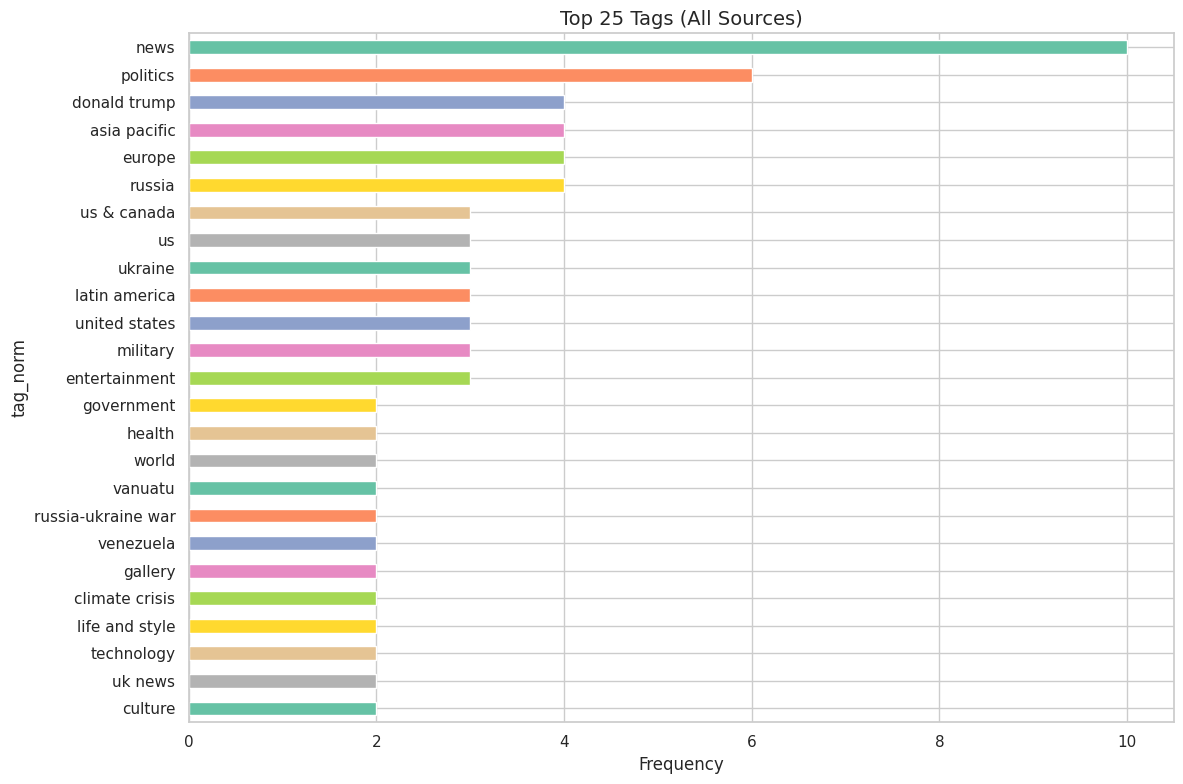

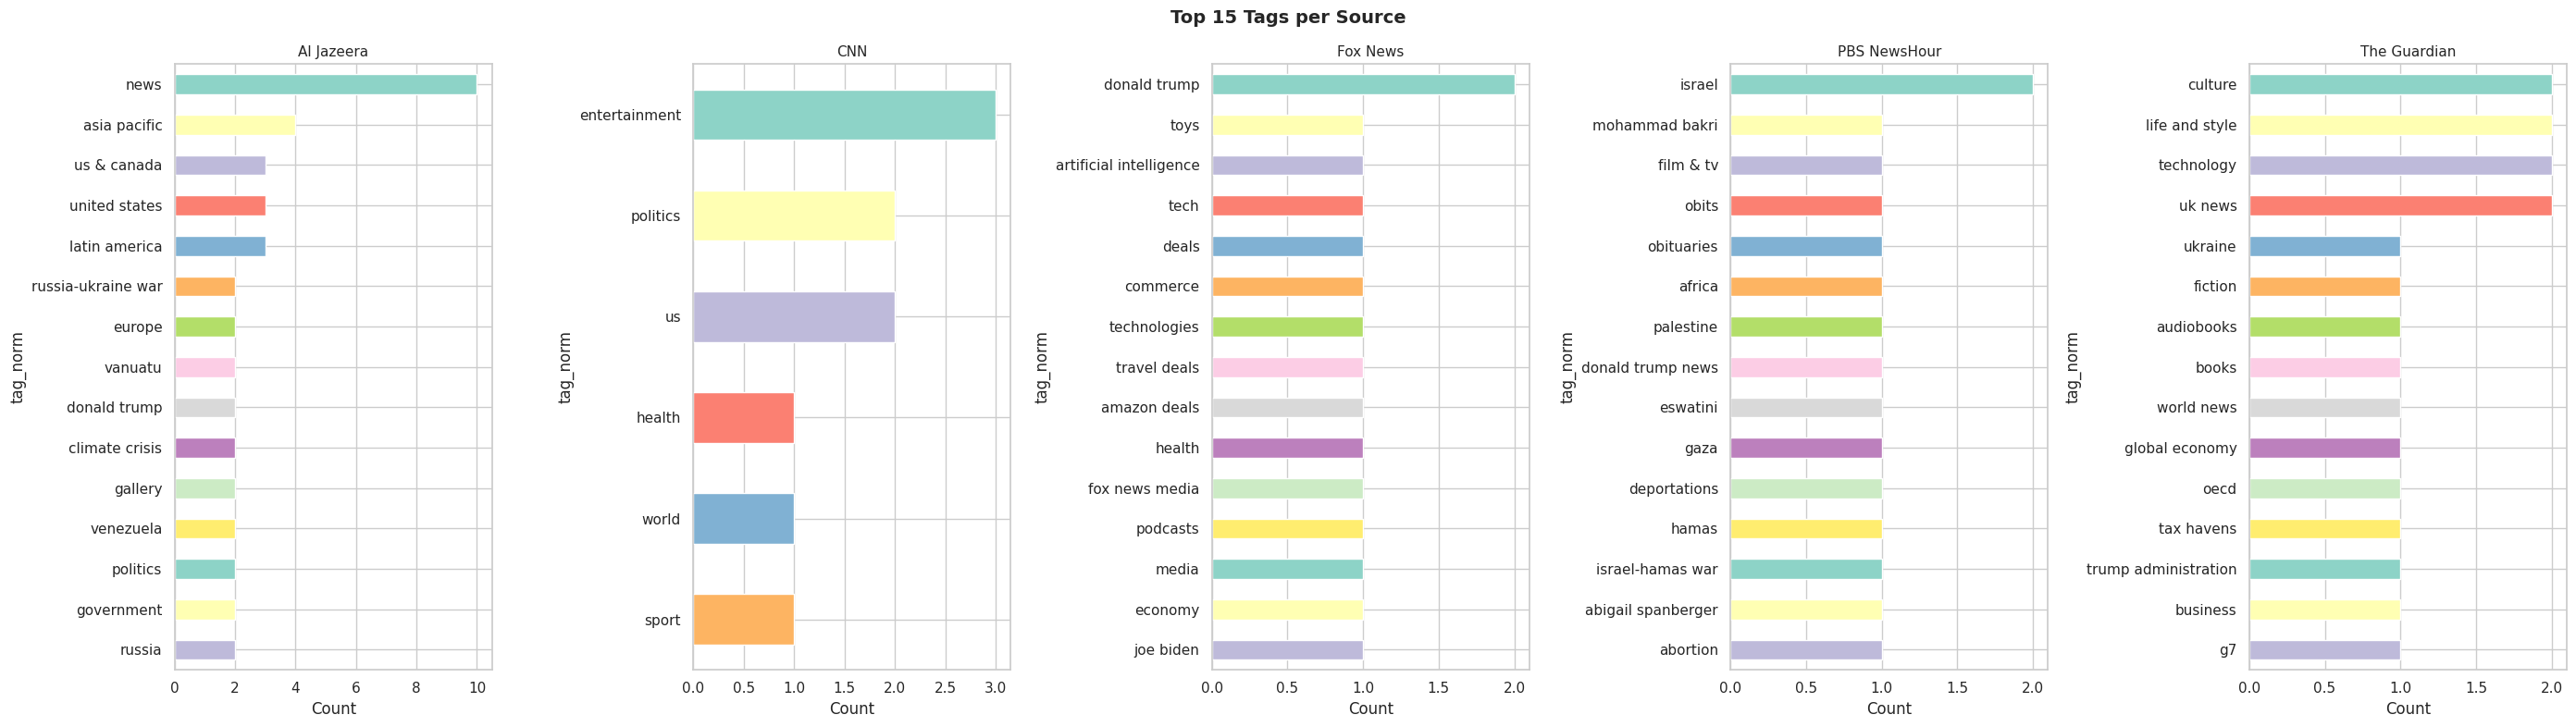


Tag-derived category coverage: 29/47 (61.7%)
Strict agreement with zero-shot: 15/29 (51.7%)
Soft agreement (incl. compatible categories): 25/29 (86.2%)

Soft-agreement pairs (compatible but not identical):
  International Affairs & Diplomacy <-> Military & Defense: 3
  Health & Medicine <-> Politics & Government: 2
  Business & Economy <-> Politics & Government: 2
  Military & Defense <-> Politics & Government: 1
  International Affairs & Diplomacy <-> Politics & Government: 1
  Business & Economy <-> Science & Technology: 1

Tag-derived vs Zero-shot Category Crosstab:
category                           Business & Economy  Crime & Justice  Entertainment & Culture  Environment & Climate  Health & Medicine  International Affairs & Diplomacy  Military & Defense  Politics & Government  Science & Technology  Sports  All
tag_derived_category                                                                                                                                                        

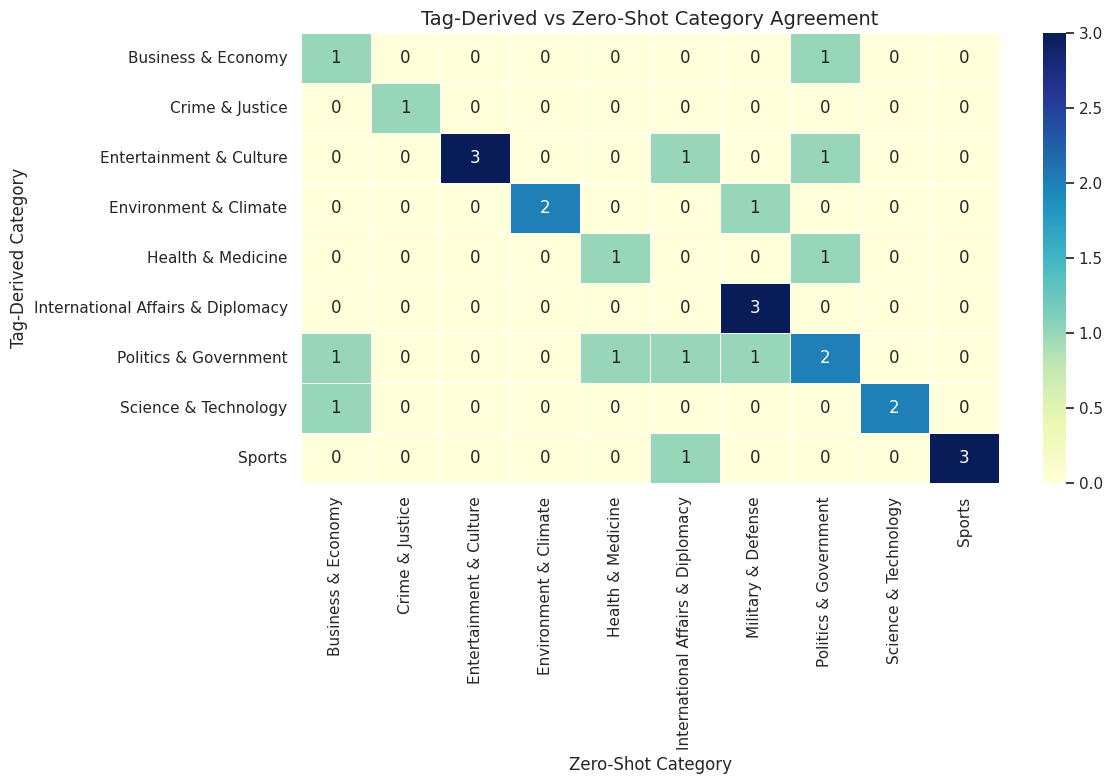


Computing tag co-occurrence pairs ...

Top 25 Tag Co-occurrence Pairs:
   1. news + politics  (2)


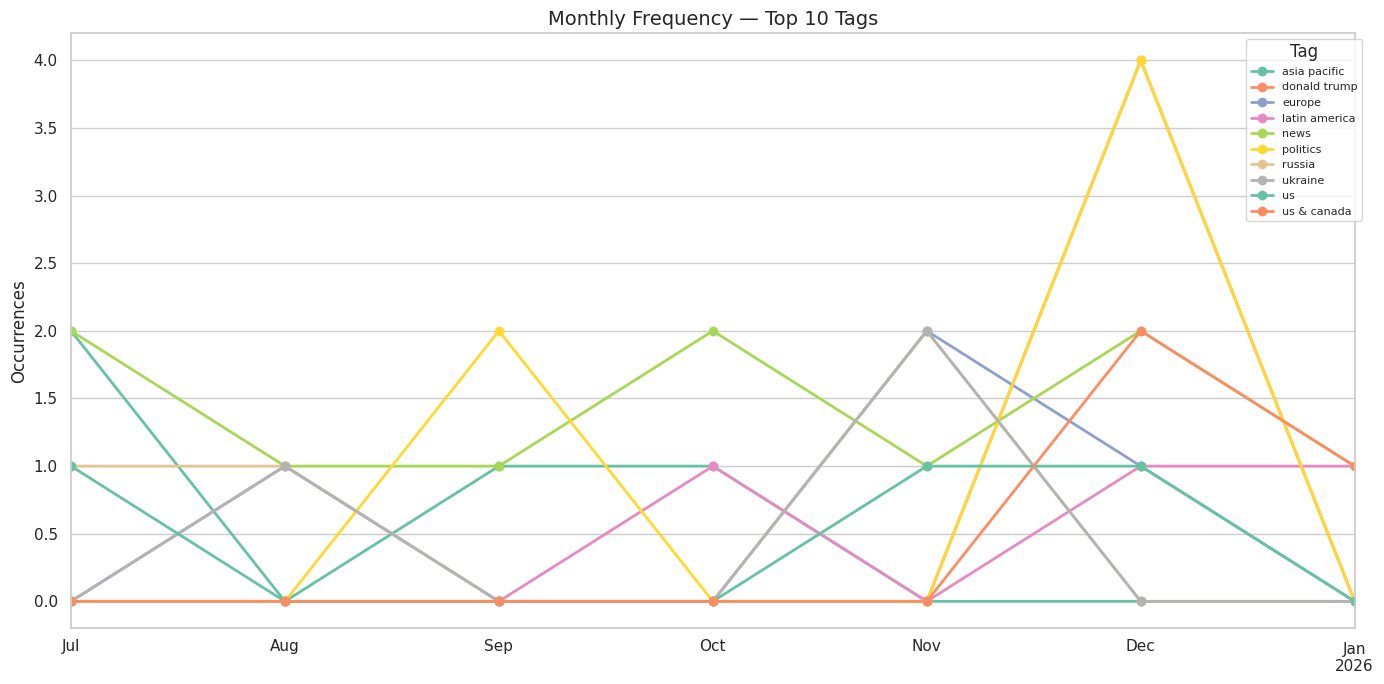

In [25]:
# ============================================================
# Tags-Based Analysis
# ============================================================
# The `tags` column has 12,635 unique tags with 99.8% coverage — the
# richest metadata signal in the dataset

import ast

def _parse_tags(val):
    """Safely parse tags column (could be list, string repr of list, or NaN)."""
    if isinstance(val, list):
        return val
    if isinstance(val, str):
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, list):
                return parsed
        except (ValueError, SyntaxError):
            pass
        # Comma-separated string fallback
        return [t.strip() for t in val.split(",") if t.strip()]
    return []


# Parse tags
df["parsed_tags"] = df["tags"].apply(_parse_tags)
df["n_tags"] = df["parsed_tags"].apply(len)

has_tags = (df["n_tags"] > 0).sum()
print(f"Articles with tags: {has_tags:,}/{len(df):,} ({has_tags/len(df)*100:.1f}%)")

# -- Tag normalization --
def _normalize_tag(tag: str) -> str:
    """Lowercase, strip, collapse whitespace."""
    return re.sub(r"\s+", " ", tag.lower().strip())

all_tags_flat = []
for idx, row in df.iterrows():
    for tag in row["parsed_tags"]:
        all_tags_flat.append({
            "article_idx": idx,
            "tag_raw": tag,
            "tag_norm": _normalize_tag(tag),
            "source": row["source"],
        })

tags_df = pd.DataFrame(all_tags_flat)
print(f"Total tag assignments: {len(tags_df):,}")
print(f"Unique normalized tags: {tags_df['tag_norm'].nunique():,}")

# -- Top tags overall and per source --
tag_freq = tags_df["tag_norm"].value_counts()
print(f"\nTop 30 Tags (overall):")
for i, (tag, count) in enumerate(tag_freq.head(30).items(), 1):
    n_src = tags_df[tags_df["tag_norm"] == tag]["source"].nunique()
    print(f"  {i:2d}. {tag:<40s}  {count:>5,}  ({n_src} sources)")

# Visualize top tags
fig, ax = plt.subplots(figsize=(12, 8))
top_tags = tag_freq.head(25)
top_tags.plot(kind="barh", ax=ax, color=sns.color_palette("Set2", len(top_tags)))
ax.invert_yaxis()
ax.set_xlabel("Frequency")
ax.set_title("Top 25 Tags (All Sources)")
plt.tight_layout()
plt.show()

# Top tags per source
fig, axes = plt.subplots(1, len(df["source"].unique()), figsize=(28, 8), sharey=False)
if not hasattr(axes, '__len__'):
    axes = [axes]
for ax, src in zip(axes, sorted(df["source"].unique())):
    src_tags = tags_df[tags_df["source"] == src]["tag_norm"].value_counts().head(15)
    src_tags.plot(kind="barh", ax=ax, color=sns.color_palette("Set3", 15))
    ax.invert_yaxis()
    ax.set_title(src, fontsize=11)
    ax.set_xlabel("Count")
plt.suptitle("Top 15 Tags per Source", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# -- Tag-derived category validation --
TAG_TO_CATEGORY_MAP = {
    # Politics & Government
    "politics": "Politics & Government",
    "us politics": "Politics & Government",
    "donald trump": "Politics & Government",
    "joe biden": "Politics & Government",
    "us elections 2024": "Politics & Government",
    "elections": "Politics & Government",
    "congress": "Politics & Government",
    "republican party": "Politics & Government",
    "democratic party": "Politics & Government",
    "white house": "Politics & Government",
    "government": "Politics & Government",
    # Business & Economy
    "business": "Business & Economy",
    "economy": "Business & Economy",
    "markets": "Business & Economy",
    "stock market": "Business & Economy",
    "trade": "Business & Economy",
    "inflation": "Business & Economy",
    # International Affairs & Diplomacy
    "foreign policy": "International Affairs & Diplomacy",
    "diplomacy": "International Affairs & Diplomacy",
    "united nations": "International Affairs & Diplomacy",
    "nato": "International Affairs & Diplomacy",
    "russia-ukraine war": "International Affairs & Diplomacy",
    "israel-gaza war": "International Affairs & Diplomacy",
    # Science & Technology
    "science": "Science & Technology",
    "technology": "Science & Technology",
    "artificial intelligence": "Science & Technology",
    "ai": "Science & Technology",
    "space": "Science & Technology",
    # Health & Medicine
    "health": "Health & Medicine",
    "medicine": "Health & Medicine",
    "covid-19": "Health & Medicine",
    "mental health": "Health & Medicine",
    # Sports
    "sport": "Sports",
    "sports": "Sports",
    "football": "Sports",
    "nfl": "Sports",
    "nba": "Sports",
    "soccer": "Sports",
    "olympics": "Sports",
    # Entertainment & Culture
    "entertainment": "Entertainment & Culture",
    "culture": "Entertainment & Culture",
    "film": "Entertainment & Culture",
    "music": "Entertainment & Culture",
    "television": "Entertainment & Culture",
    "books": "Entertainment & Culture",
    # Crime & Justice
    "crime": "Crime & Justice",
    "law": "Crime & Justice",
    "courts": "Crime & Justice",
    "police": "Crime & Justice",
    "supreme court": "Crime & Justice",
    # Environment & Climate
    "environment": "Environment & Climate",
    "climate": "Environment & Climate",
    "climate crisis": "Environment & Climate",
    "climate change": "Environment & Climate",
    "energy": "Environment & Climate",
    # Education
    "education": "Education",
    "schools": "Education",
    "universities": "Education",
    # Military & Defense
    "military": "Military & Defense",
    "defense": "Military & Defense",
    "pentagon": "Military & Defense",
    "armed forces": "Military & Defense",
}

# -- Soft agreement: category compatibility matrix --
# Many "disagreements" are actually related categories covering the same article
# from different angles (e.g., a foreign policy article tagged as Politics but
# zero-shot classified as International Affairs). This matrix defines which
# category pairs are considered compatible for a "soft agreement" metric.
COMPATIBLE_CATEGORIES = {
    frozenset({"Politics & Government", "International Affairs & Diplomacy"}),
    frozenset({"Politics & Government", "Military & Defense"}),
    frozenset({"Politics & Government", "Crime & Justice"}),
    frozenset({"Politics & Government", "Health & Medicine"}),
    frozenset({"Politics & Government", "Business & Economy"}),
    frozenset({"International Affairs & Diplomacy", "Military & Defense"}),
    frozenset({"Science & Technology", "Business & Economy"}),
    frozenset({"Science & Technology", "Health & Medicine"}),
    frozenset({"Environment & Climate", "Science & Technology"}),
    frozenset({"Environment & Climate", "Politics & Government"}),
    frozenset({"Crime & Justice", "Military & Defense"}),
    frozenset({"Health & Medicine", "Science & Technology"}),
}

def _is_soft_agree(cat_a: str, cat_b: str) -> bool:
    """Check if two categories are either identical or compatible."""
    if cat_a == cat_b:
        return True
    return frozenset({cat_a, cat_b}) in COMPATIBLE_CATEGORIES


def _tag_derived_category(tags_list):
    """Derive category from tags using the mapping. Returns most frequent match or None."""
    cats = []
    for tag in tags_list:
        norm = _normalize_tag(tag)
        if norm in TAG_TO_CATEGORY_MAP:
            cats.append(TAG_TO_CATEGORY_MAP[norm])
    if not cats:
        return None
    return Counter(cats).most_common(1)[0][0]

df["tag_derived_category"] = df["parsed_tags"].apply(_tag_derived_category)
tag_cat_coverage = df["tag_derived_category"].notna().sum()
print(f"\nTag-derived category coverage: {tag_cat_coverage:,}/{len(df):,} "
      f"({tag_cat_coverage/len(df)*100:.1f}%)")

# Compare tag-derived vs zero-shot categories
if tag_cat_coverage > 0:
    mask = df["tag_derived_category"].notna()
    agree = (df.loc[mask, "category"] == df.loc[mask, "tag_derived_category"]).sum()
    soft_agree = df.loc[mask].apply(
        lambda r: _is_soft_agree(r["category"], r["tag_derived_category"]), axis=1
    ).sum()
    print(f"Strict agreement with zero-shot: {agree:,}/{mask.sum():,} "
          f"({agree/mask.sum()*100:.1f}%)")
    print(f"Soft agreement (incl. compatible categories): {soft_agree:,}/{mask.sum():,} "
          f"({soft_agree/mask.sum()*100:.1f}%)")

    # Show which compatible-category pairs account for the soft gains
    soft_only = df.loc[mask].apply(
        lambda r: _is_soft_agree(r["category"], r["tag_derived_category"])
                  and r["category"] != r["tag_derived_category"],
        axis=1,
    )
    if soft_only.sum() > 0:
        soft_rows = df.loc[mask][soft_only]
        print(f"\nSoft-agreement pairs (compatible but not identical):")
        pair_counts = Counter()
        for _, r in soft_rows.iterrows():
            pair = tuple(sorted([r["tag_derived_category"], r["category"]]))
            pair_counts[pair] += 1
        for (a, b), cnt in pair_counts.most_common():
            print(f"  {a} <-> {b}: {cnt}")

    # Confusion-style crosstab
    ct_validation = pd.crosstab(
        df.loc[mask, "tag_derived_category"],
        df.loc[mask, "category"],
        margins=True,
    )
    print("\nTag-derived vs Zero-shot Category Crosstab:")
    print(ct_validation.to_string())

    # Heatmap
    ct_no_margin = pd.crosstab(
        df.loc[mask, "tag_derived_category"],
        df.loc[mask, "category"],
    )
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(ct_no_margin, annot=True, fmt="d", cmap="YlGnBu",
                ax=ax, linewidths=0.5)
    ax.set_title("Tag-Derived vs Zero-Shot Category Agreement")
    ax.set_xlabel("Zero-Shot Category")
    ax.set_ylabel("Tag-Derived Category")
    plt.tight_layout()
    plt.show()

# -- Tag co-occurrence analysis --
print("\nComputing tag co-occurrence pairs ...")

# For each article, find all pairs of its normalized tags
cooccurrence = Counter()
for tags_list in df["parsed_tags"]:
    norm_tags = sorted(set(_normalize_tag(t) for t in tags_list))
    # Only consider tags that appear in at least a few articles (performance)
    freq_tags = [t for t in norm_tags if tag_freq.get(t, 0) >= 5]
    for a, b in combinations(freq_tags, 2):
        cooccurrence[(a, b)] += 1

top_pairs = cooccurrence.most_common(25)
if top_pairs:
    print(f"\nTop 25 Tag Co-occurrence Pairs:")
    for i, ((a, b), count) in enumerate(top_pairs, 1):
        print(f"  {i:2d}. {a} + {b}  ({count:,})")

# -- Tag temporal trends --
if not TEST_MODE or df["pub_month"].nunique() > 1:
    # Pick top 10 most frequent tags for temporal analysis
    top_temporal_tags = tag_freq.head(10).index.tolist()
    temp_tag_data = tags_df[tags_df["tag_norm"].isin(top_temporal_tags)]

    # Merge pub_month
    temp_tag_data = temp_tag_data.merge(
        df[["pub_month"]], left_on="article_idx", right_index=True, how="left",
    )
    monthly_tags = temp_tag_data.groupby(["pub_month", "tag_norm"]).size().unstack(fill_value=0)

    fig, ax = plt.subplots(figsize=(14, 7))
    monthly_tags.plot(ax=ax, marker="o", linewidth=2)
    ax.set_title("Monthly Frequency — Top 10 Tags")
    ax.set_ylabel("Occurrences")
    ax.set_xlabel("")
    ax.legend(title="Tag", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.tight_layout()
    plt.show()

# Clean up intermediate columns
df.drop(columns=["parsed_tags", "n_tags"], inplace=True, errors="ignore")

ARTICLE-LEVEL SENTIMENT (mean of full article)
NOTE: These values reflect the mean sentiment of the ENTIRE article
in which a figure is mentioned, not the sentiment of text specifically
about that figure. This is the ecological-fallacy baseline.



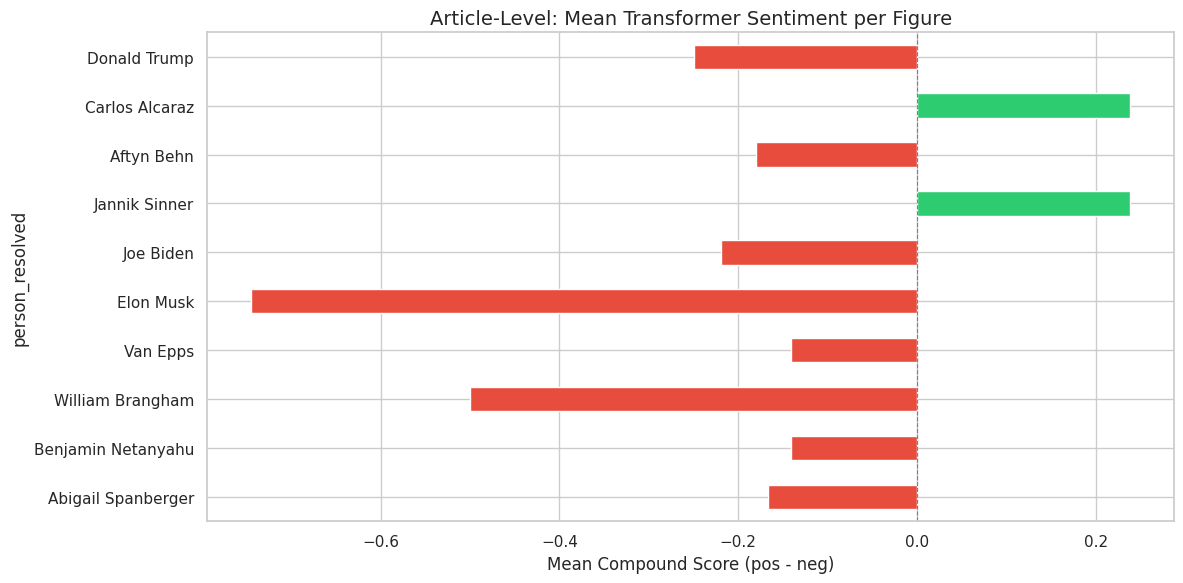


SENTENCE-LEVEL SENTIMENT (sentences mentioning each figure)
Running sentence-level sentiment on 187 unique sentences ...
Loading sentiment model: j-hartmann/sentiment-roberta-large-english-3-classes


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: j-hartmann/sentiment-roberta-large-english-3-classes
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Sentence sentiment:   0%|          | 0/6 [00:00<?, ?it/s]

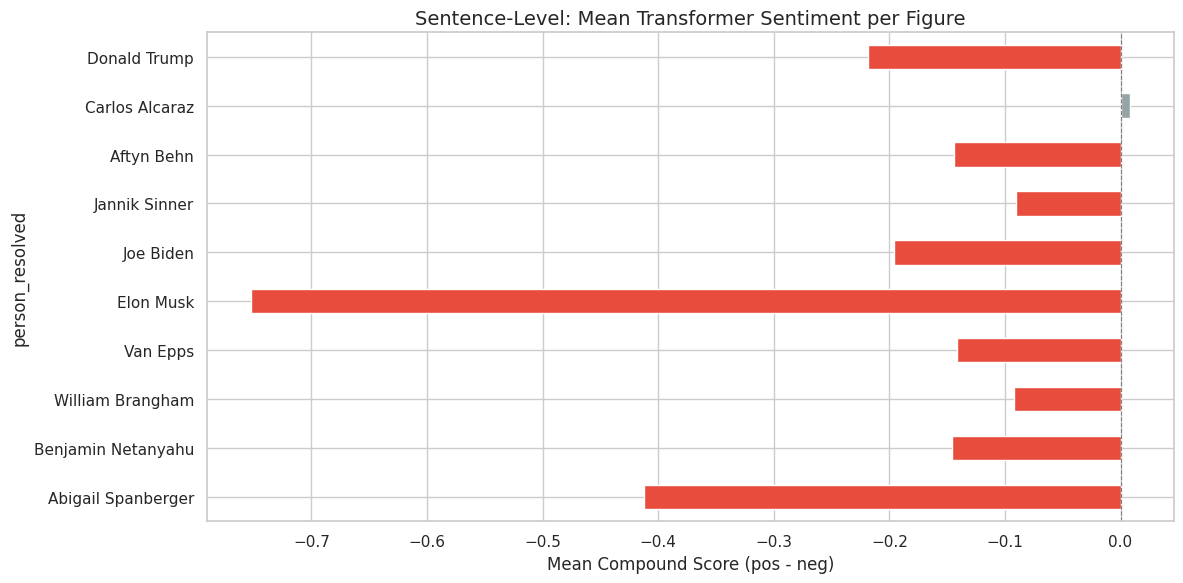

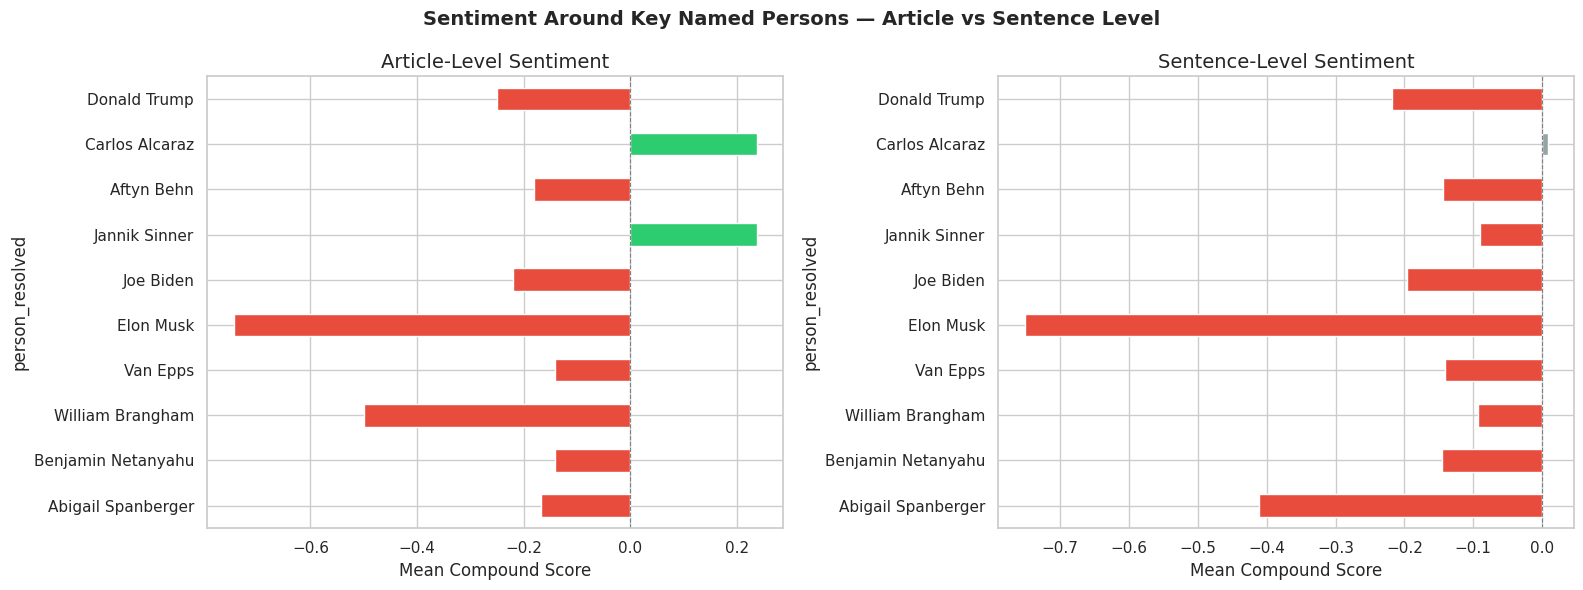

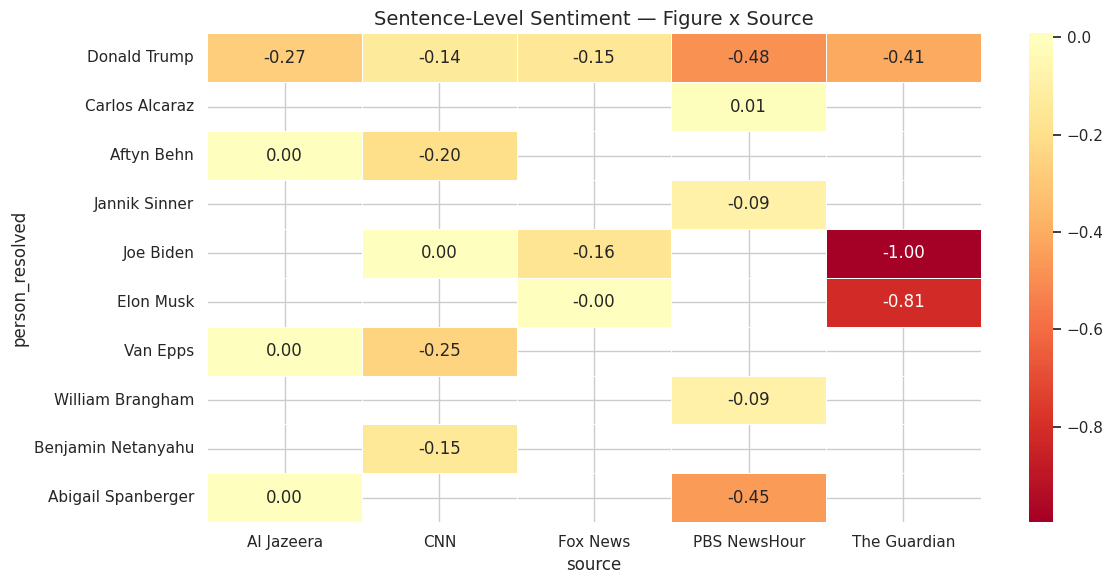


Sentences per figure (top 10):
  Donald Trump                      95 sentences  mean_compound=-0.219
  Carlos Alcaraz                    24 sentences  mean_compound=+0.008
  Aftyn Behn                        21 sentences  mean_compound=-0.144
  Jannik Sinner                     20 sentences  mean_compound=-0.091
  Joe Biden                         16 sentences  mean_compound=-0.196
  Elon Musk                         14 sentences  mean_compound=-0.752
  Van Epps                          14 sentences  mean_compound=-0.142
  William Brangham                   4 sentences  mean_compound=-0.092
  Benjamin Netanyahu                12 sentences  mean_compound=-0.146
  Abigail Spanberger                11 sentences  mean_compound=-0.412


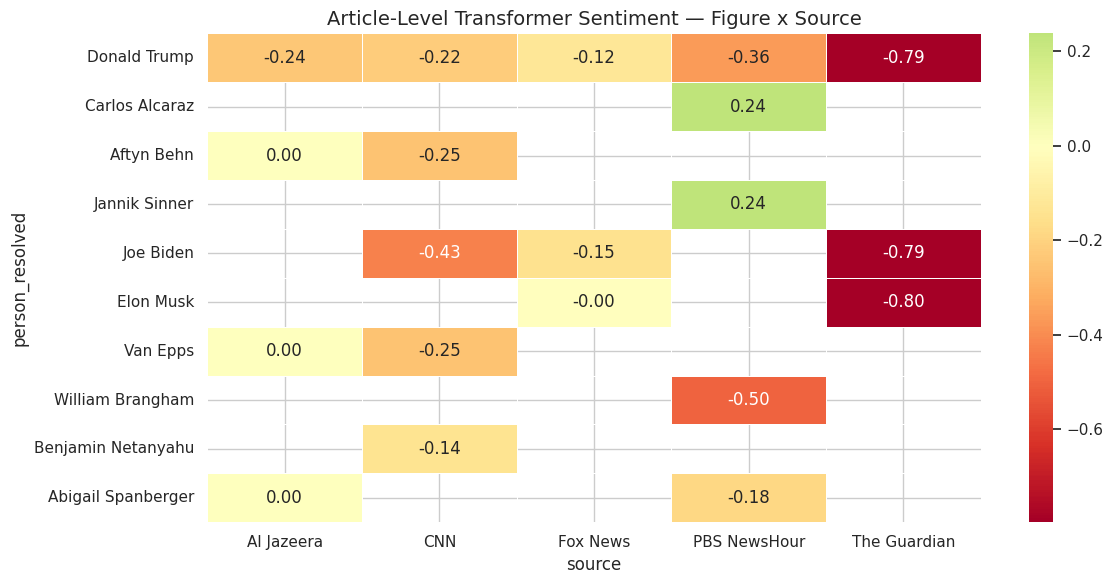

In [26]:
# ============================================================
# Sentiment Around Key Political Figures
# ============================================================
# shows BOTH article-level AND sentence-level sentiment.
# Article-level = mean sentiment of the entire article mentioning the figure.
# Sentence-level = sentiment of individual sentences containing the figure.

if len(persons_df) > 0 and "person_resolved" in persons_df.columns:
    top_figures = person_freq.head(10).index.tolist()
    fig_df = persons_df[persons_df["person_resolved"].isin(top_figures)]

    # ================================================================
    # PART 1: Article-Level Sentiment
    # ================================================================
    print("=" * 60)
    print("ARTICLE-LEVEL SENTIMENT (mean of full article)")
    print("=" * 60)
    print("NOTE: These values reflect the mean sentiment of the ENTIRE article")
    print("in which a figure is mentioned, not the sentiment of text specifically")
    print("about that figure. This is the ecological-fallacy baseline.\n")

    fig_sent_t = fig_df.groupby("person_resolved")["trans_content_compound"].mean()
    fig_sent_t = fig_sent_t.reindex(top_figures).dropna()

    fig, ax = plt.subplots(figsize=(12, 6))
    colors_t = ["#e74c3c" if v < -0.05 else "#2ecc71" if v > 0.05 else "#95a5a6"
                for v in fig_sent_t.values]
    fig_sent_t.plot(kind="barh", ax=ax, color=colors_t)
    ax.set_title("Article-Level: Mean Transformer Sentiment per Figure")
    ax.set_xlabel("Mean Compound Score (pos - neg)")
    ax.axvline(0, color="grey", ls="--", lw=0.8)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

    # ================================================================
    # PART 2: Sentence-Level Sentiment
    # ================================================================
    print("\n" + "=" * 60)
    print("SENTENCE-LEVEL SENTIMENT (sentences mentioning each figure)")
    print("=" * 60)

    if ("person_sentences_df_enriched" in dir() and
            len(person_sentences_df_enriched) > 0):

        # Filter to top figures
        sent_fig = person_sentences_df_enriched[
            person_sentences_df_enriched["person_resolved"].isin(top_figures)
        ].copy()

        if len(sent_fig) > 0:
            # Get unique sentences to avoid re-scoring duplicates
            unique_sents = sent_fig["sentence"].unique().tolist()
            print(f"Running sentence-level sentiment on {len(unique_sents):,} unique sentences ...")

            # Reload sentiment model for sentence scoring
            print(f"Loading sentiment model: {SENTIMENT_MODEL}")
            _sent_pipe = hf_pipeline(
                "sentiment-analysis",
                model=SENTIMENT_MODEL,
                tokenizer=SENTIMENT_MODEL,
                device=DEVICE,
                top_k=None,
            )

            # Score all unique sentences
            sent_scores = {}
            for j in tqdm(range(0, len(unique_sents), BATCH_SENTIMENT),
                          desc="Sentence sentiment"):
                batch = unique_sents[j : j + BATCH_SENTIMENT]
                results = _sent_pipe(batch, truncation=True, max_length=512)
                for text, result in zip(batch, results):
                    score_map = {_normalize_label(item["label"]): item["score"]
                                 for item in result}
                    compound = score_map.get("positive", 0) - score_map.get("negative", 0)
                    best = max(score_map, key=score_map.get)
                    sent_scores[text] = {"label": best, "compound": compound}

            # Free GPU memory
            del _sent_pipe
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            # Map scores back to the figure-sentence dataframe
            sent_fig["sent_label"] = sent_fig["sentence"].map(
                lambda s: sent_scores.get(s, {}).get("label", "neutral")
            )
            sent_fig["sent_compound"] = sent_fig["sentence"].map(
                lambda s: sent_scores.get(s, {}).get("compound", 0.0)
            )

            # --- Sentence-level bar chart ---
            sent_fig_mean = sent_fig.groupby("person_resolved")["sent_compound"].mean()
            sent_fig_mean = sent_fig_mean.reindex(top_figures).dropna()

            fig, ax = plt.subplots(figsize=(12, 6))
            colors_s = ["#e74c3c" if v < -0.05 else "#2ecc71" if v > 0.05 else "#95a5a6"
                        for v in sent_fig_mean.values]
            sent_fig_mean.plot(kind="barh", ax=ax, color=colors_s)
            ax.set_title("Sentence-Level: Mean Transformer Sentiment per Figure")
            ax.set_xlabel("Mean Compound Score (pos - neg)")
            ax.axvline(0, color="grey", ls="--", lw=0.8)
            ax.invert_yaxis()
            plt.tight_layout()
            plt.show()

            # --- Side-by-side comparison ---
            fig, axes = plt.subplots(1, 2, figsize=(16, 6))

            for ax_i, (data, title) in enumerate([
                (fig_sent_t, "Article-Level"),
                (sent_fig_mean, "Sentence-Level"),
            ]):
                colors = ["#e74c3c" if v < -0.05 else "#2ecc71" if v > 0.05 else "#95a5a6"
                          for v in data.values]
                data.plot(kind="barh", ax=axes[ax_i], color=colors)
                axes[ax_i].set_title(f"{title} Sentiment")
                axes[ax_i].set_xlabel("Mean Compound Score")
                axes[ax_i].axvline(0, color="grey", ls="--", lw=0.8)
                axes[ax_i].invert_yaxis()

            plt.suptitle("Sentiment Around Key Named Persons — Article vs Sentence Level",
                         fontsize=14, fontweight="bold")
            plt.tight_layout()
            plt.show()

            # --- Sentence-level sentiment per figure per source heatmap ---
            pivot_sent = sent_fig.pivot_table(
                index="person_resolved", columns="source",
                values="sent_compound", aggfunc="mean",
            )
            pivot_sent = pivot_sent.loc[[f for f in top_figures if f in pivot_sent.index]]

            fig, ax = plt.subplots(figsize=(12, 6))
            sns.heatmap(pivot_sent, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
                        ax=ax, linewidths=0.5)
            ax.set_title("Sentence-Level Sentiment — Figure x Source")
            plt.tight_layout()
            plt.show()

            # Store sentence-level data for later cells
            _sentence_sentiment_available = True
            _sent_fig = sent_fig
            _sent_fig_mean = sent_fig_mean

            # Summary stats
            n_sents_per_fig = sent_fig.groupby("person_resolved").size()
            print(f"\nSentences per figure (top 10):")
            for fig_name in top_figures:
                if fig_name in n_sents_per_fig.index:
                    n = n_sents_per_fig[fig_name]
                    mean_s = sent_fig[sent_fig["person_resolved"] == fig_name]["sent_compound"].mean()
                    print(f"  {fig_name:<30s}  {n:>4} sentences  mean_compound={mean_s:+.3f}")
        else:
            print("No sentence data for top figures.")
            _sentence_sentiment_available = False
    else:
        print("No person-sentence data available. Skipping sentence-level analysis.")
        _sentence_sentiment_available = False

    # --- Article-level heatmap (figure x source) ---
    pivot = fig_df.pivot_table(
        index="person_resolved", columns="source",
        values="trans_content_compound", aggfunc="mean",
    )
    pivot = pivot.loc[[f for f in top_figures if f in pivot.index]]

    fig, ax = plt.subplots(figsize=(12, 6))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
                ax=ax, linewidths=0.5)
    ax.set_title("Article-Level Transformer Sentiment — Figure x Source")
    plt.tight_layout()
    plt.show()

else:
    print("Skipping figure sentiment analysis (no person entities found).")
    _sentence_sentiment_available = False


ARTICLE vs SENTENCE LEVEL SENTIMENT COMPARISON

Spearman correlation (article vs sentence compound): rho = 0.369, p = 7.57e-09

Per-figure sentiment comparison (article-level vs sentence-level):
  Figure                           Article  Sentence     Delta  N_sent
  ------------------------------  --------  --------  --------  ------
  Donald Trump                      -0.250    -0.219    +0.031      95
  Carlos Alcaraz                    +0.238    +0.008    -0.230      24
  Aftyn Behn                        -0.180    -0.144    +0.036      21
  Jannik Sinner                     +0.238    -0.091    -0.329      20
  Joe Biden                         -0.219    -0.196    +0.023      16
  Elon Musk                         -0.744    -0.752    -0.008      14
  Van Epps                          -0.141    -0.142    -0.001      14
  William Brangham                  -0.500    -0.092    +0.408       4
  Benjamin Netanyahu                -0.142    -0.146    -0.005      12
  Abigail Spanberger    

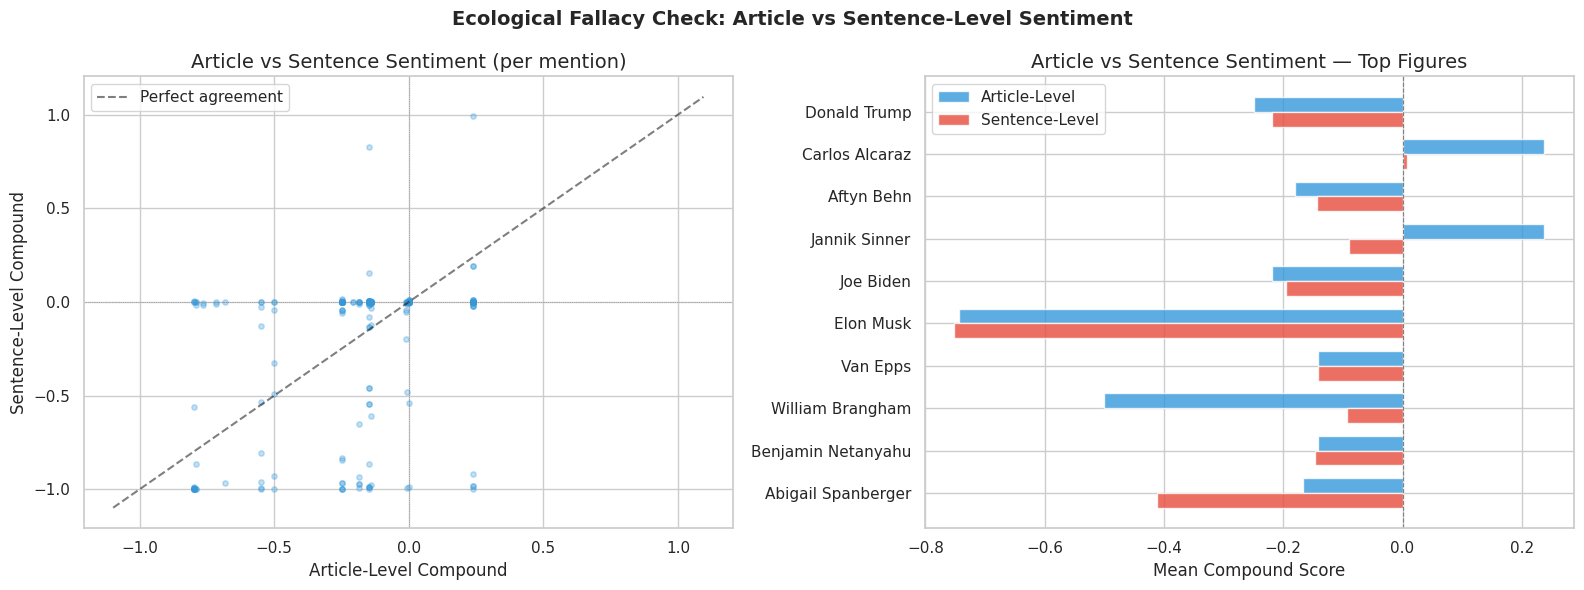


Label agreement (article vs sentence): 34.2%
Cohen's Kappa (article vs sentence labels): 0.103


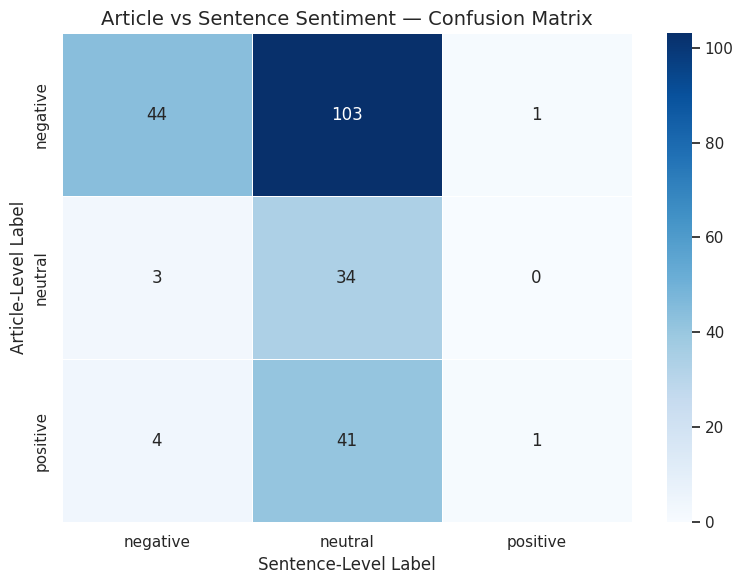


Mean Absolute Deviation (sentence vs article compound): 0.289

Per-source article vs sentence sentiment:
  Al Jazeera            article=-0.152  sentence=-0.170  delta=-0.017  (n=35)
  CNN                   article=-0.218  sentence=-0.164  delta=+0.054  (n=67)
  Fox News              article=-0.126  sentence=-0.151  delta=-0.026  (n=43)
  PBS NewsHour          article=+0.063  sentence=-0.152  delta=-0.215  (n=65)
  The Guardian          article=-0.796  sentence=-0.685  delta=+0.110  (n=21)


In [27]:
# ============================================================
# Article-Level vs Sentence-Level Sentiment Comparison
# ============================================================

print("=" * 60)
print("ARTICLE vs SENTENCE LEVEL SENTIMENT COMPARISON")
print("=" * 60)

if ("_sentence_sentiment_available" in dir() and _sentence_sentiment_available
        and len(_sent_fig) > 0):

    # For each figure mention, we have:
    #   - Article-level compound: from the persons_df (trans_content_compound)
    #   - Sentence-level compound: from _sent_fig (sent_compound)

    # Merge article-level sentiment into the sentence-level data
    comparison_df = _sent_fig.merge(
        df[["trans_content_compound"]],
        left_on="article_idx", right_index=True, how="left",
    )

    # -- Correlation between article-level and sentence-level --
    if len(comparison_df) >= 10:
        rho, p_val = stats.spearmanr(
            comparison_df["trans_content_compound"],
            comparison_df["sent_compound"],
        )
        print(f"\nSpearman correlation (article vs sentence compound): "
              f"rho = {rho:.3f}, p = {p_val:.2e}")

    # -- Per-figure comparison --
    print("\nPer-figure sentiment comparison (article-level vs sentence-level):")
    print(f"  {'Figure':<30s}  {'Article':>8s}  {'Sentence':>8s}  {'Delta':>8s}  {'N_sent':>6s}")
    print(f"  {'-'*30}  {'-'*8}  {'-'*8}  {'-'*8}  {'-'*6}")

    top_figures = person_freq.head(10).index.tolist()
    article_means = []
    sentence_means = []

    for fig_name in top_figures:
        mask_art = persons_df["person_resolved"] == fig_name
        mask_sent = comparison_df["person_resolved"] == fig_name

        if mask_art.sum() == 0 or mask_sent.sum() == 0:
            continue

        art_mean = persons_df.loc[mask_art, "trans_content_compound"].mean()
        sent_mean = comparison_df.loc[mask_sent, "sent_compound"].mean()
        delta = sent_mean - art_mean
        n_sent = mask_sent.sum()

        article_means.append(art_mean)
        sentence_means.append(sent_mean)

        print(f"  {fig_name:<30s}  {art_mean:>+8.3f}  {sent_mean:>+8.3f}  "
              f"{delta:>+8.3f}  {n_sent:>6,}")

    # -- Scatter plot: article vs sentence compound --
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # a — Scatter
    axes[0].scatter(
        comparison_df["trans_content_compound"],
        comparison_df["sent_compound"],
        alpha=0.3, s=15, c="#3498db",
    )
    # Add diagonal line
    lims = [
        min(comparison_df["trans_content_compound"].min(),
            comparison_df["sent_compound"].min()) - 0.1,
        max(comparison_df["trans_content_compound"].max(),
            comparison_df["sent_compound"].max()) + 0.1,
    ]
    axes[0].plot(lims, lims, "k--", alpha=0.5, label="Perfect agreement")
    axes[0].set_xlabel("Article-Level Compound")
    axes[0].set_ylabel("Sentence-Level Compound")
    axes[0].set_title("Article vs Sentence Sentiment (per mention)")
    axes[0].legend()
    axes[0].axhline(0, color="grey", ls=":", lw=0.5)
    axes[0].axvline(0, color="grey", ls=":", lw=0.5)

    # b — Bar chart comparison for top figures
    if article_means and sentence_means:
        x = np.arange(len(top_figures[:len(article_means)]))
        width = 0.35
        axes[1].barh(x - width/2, article_means, width, label="Article-Level",
                     color="#3498db", alpha=0.8)
        axes[1].barh(x + width/2, sentence_means, width, label="Sentence-Level",
                     color="#e74c3c", alpha=0.8)
        axes[1].set_yticks(x)
        axes[1].set_yticklabels(top_figures[:len(article_means)])
        axes[1].set_xlabel("Mean Compound Score")
        axes[1].set_title("Article vs Sentence Sentiment — Top Figures")
        axes[1].legend()
        axes[1].axvline(0, color="grey", ls="--", lw=0.8)
        axes[1].invert_yaxis()

    plt.suptitle("Ecological Fallacy Check: Article vs Sentence-Level Sentiment",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # -- Label-level agreement --
    # Derive article-level label from compound for comparison
    def _compound_to_label(c):
        if c > 0.05: return "positive"
        if c < -0.05: return "negative"
        return "neutral"

    comparison_df["art_label"] = comparison_df["trans_content_compound"].apply(_compound_to_label)
    label_agree = (comparison_df["art_label"] == comparison_df["sent_label"]).mean()
    print(f"\nLabel agreement (article vs sentence): {label_agree:.1%}")

    if len(comparison_df) >= 10:
        try:
            kappa = cohen_kappa_score(comparison_df["art_label"], comparison_df["sent_label"])
            print(f"Cohen's Kappa (article vs sentence labels): {kappa:.3f}")
        except ValueError:
            pass

    # Confusion matrix
    labels_ordered = ["negative", "neutral", "positive"]
    cm = confusion_matrix(
        comparison_df["art_label"], comparison_df["sent_label"],
        labels=labels_ordered,
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels_ordered, yticklabels=labels_ordered,
                ax=ax, linewidths=0.5)
    ax.set_xlabel("Sentence-Level Label")
    ax.set_ylabel("Article-Level Label")
    ax.set_title("Article vs Sentence Sentiment — Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # Mean absolute deviation
    mad = (comparison_df["sent_compound"] - comparison_df["trans_content_compound"]).abs().mean()
    print(f"\nMean Absolute Deviation (sentence vs article compound): {mad:.3f}")

    # Per-source comparison
    print("\nPer-source article vs sentence sentiment:")
    for src in sorted(comparison_df["source"].unique()):
        mask = comparison_df["source"] == src
        if mask.sum() < 5:
            continue
        art_m = comparison_df.loc[mask, "trans_content_compound"].mean()
        sent_m = comparison_df.loc[mask, "sent_compound"].mean()
        print(f"  {src:<20s}  article={art_m:+.3f}  sentence={sent_m:+.3f}  "
              f"delta={sent_m - art_m:+.3f}  (n={mask.sum():,})")

else:
    print("\nSentence-level sentiment data not available.")
    print("This comparison requires the sentence-level sentiment from the")
    print("'Sentiment Around Key Named Persons' cell to have run successfully.")


Computing TF-IDF top terms per source ...


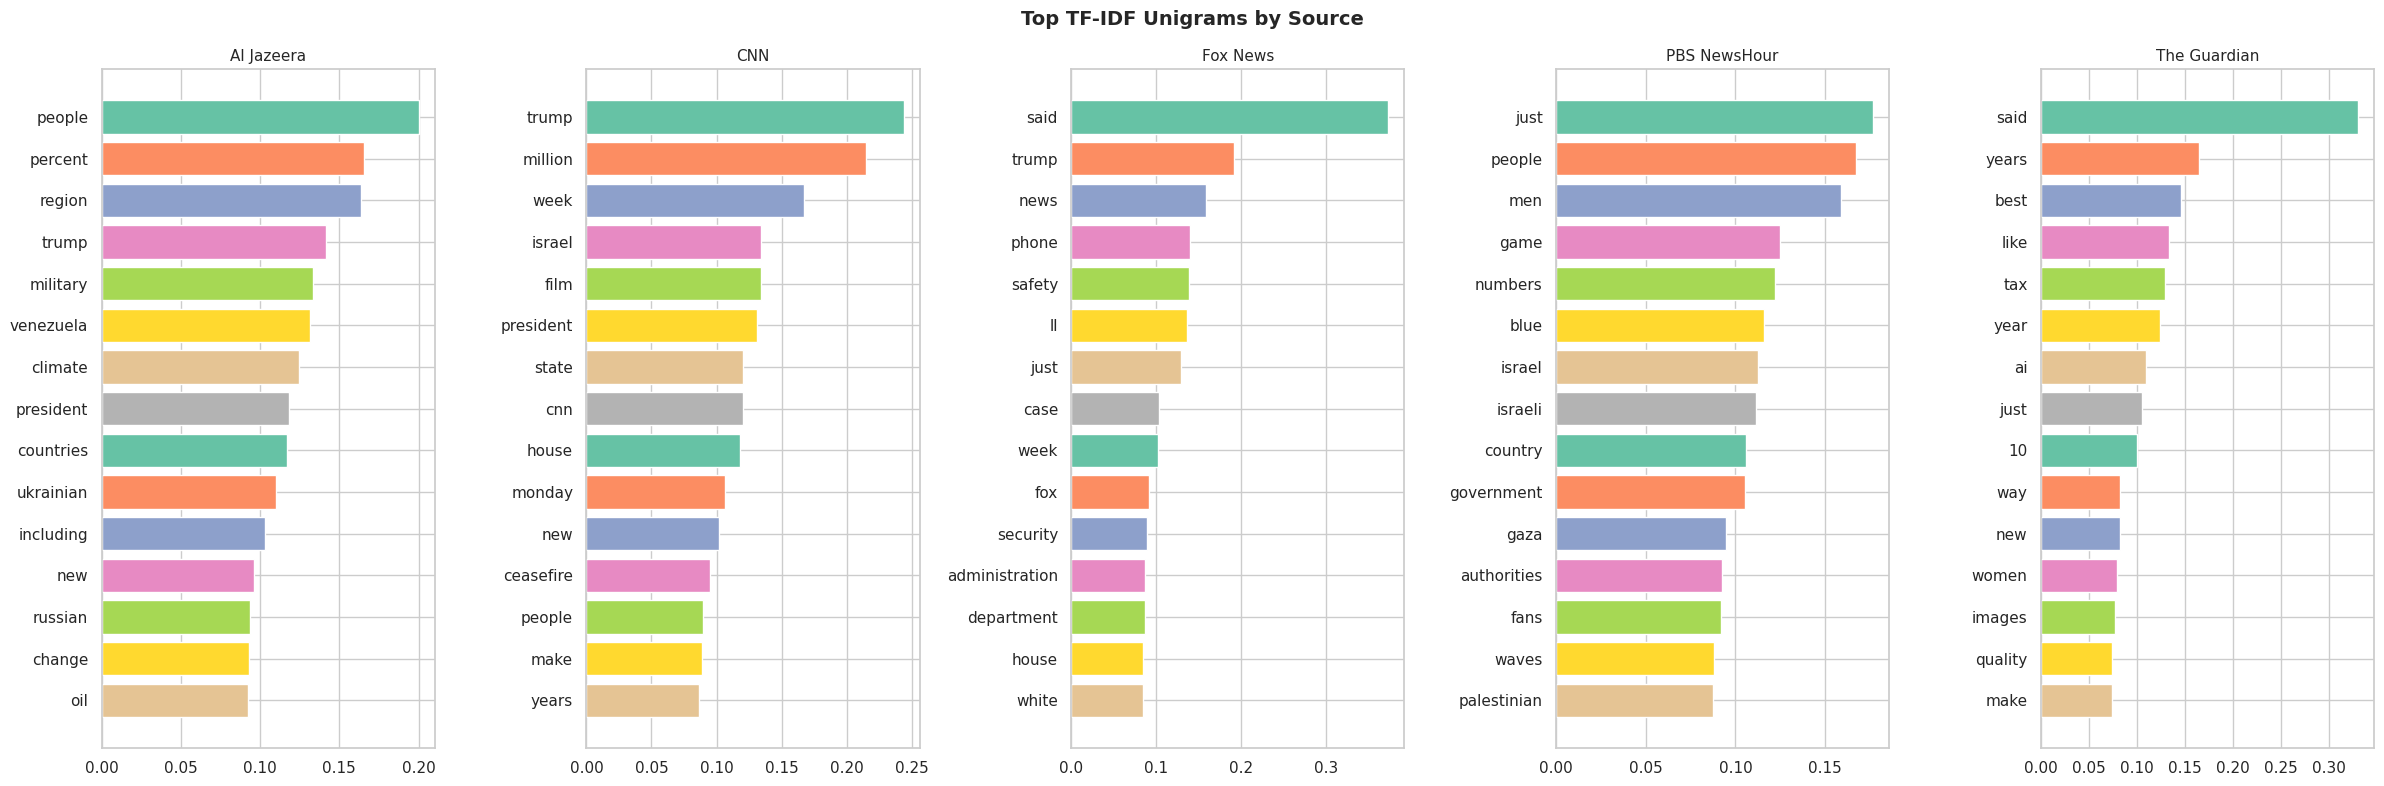

Computing top bigrams per source ...


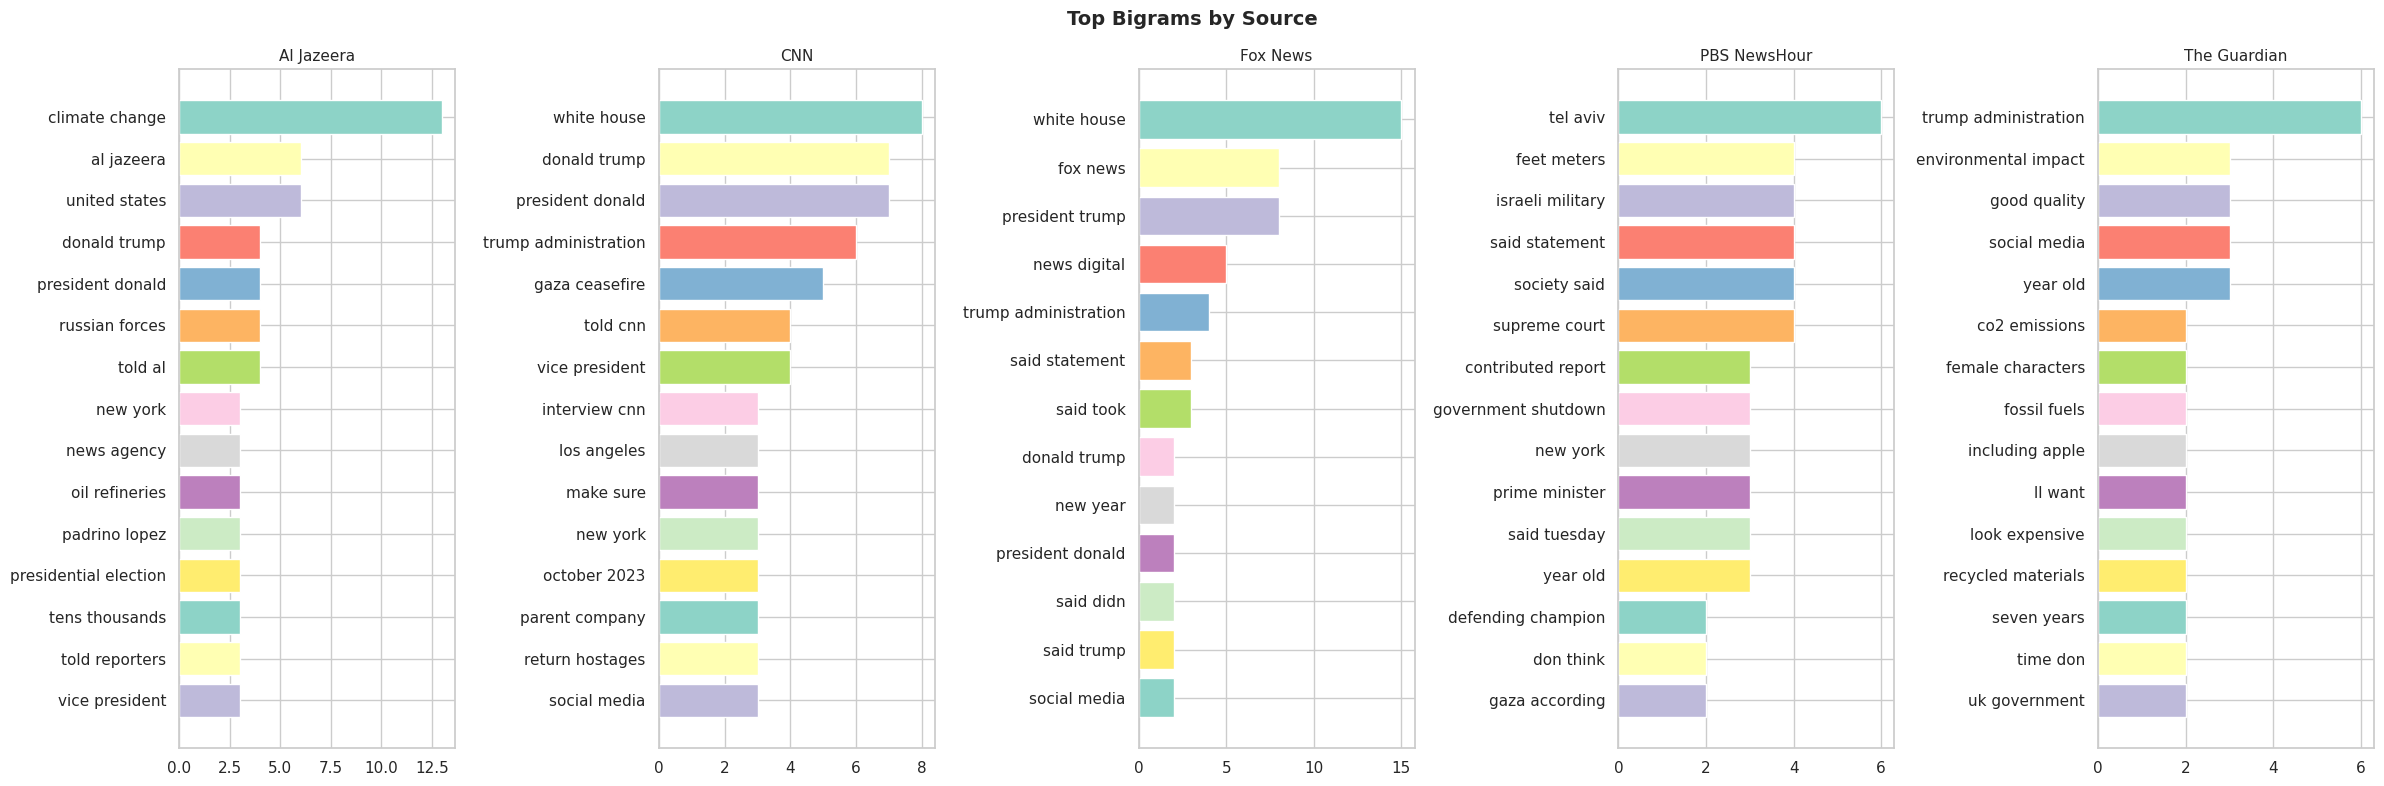

Computing readability scores ...
  Excluding 0 articles with < 100 words from readability.


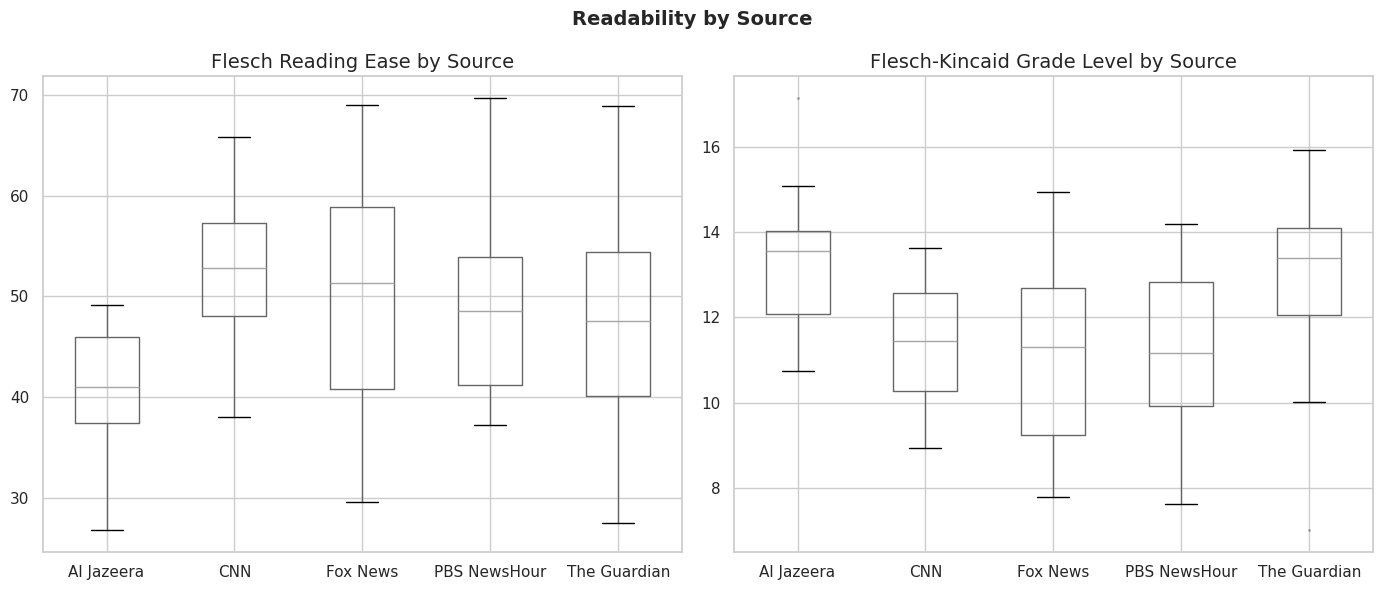


Readability Statistics by Source (articles with ≥ 100 words):
             flesch_reading_ease                                           flesch_kincaid_grade                                         
                           count  mean   std   min   25%   50%   75%   max                count  mean  std   min   25%   50%   75%   max
source                                                                                                                                  
Al Jazeera                  10.0  40.8   7.0  26.7  37.4  41.0  45.9  49.2                 10.0  13.4  1.8  10.7  12.1  13.5  14.0  17.1
CNN                         10.0  51.9   8.7  38.0  48.1  52.8  57.3  65.9                 10.0  11.3  1.6   8.9  10.3  11.4  12.6  13.6
Fox News                     8.0  50.1  14.1  29.6  40.8  51.3  58.9  69.0                  8.0  11.2  2.7   7.8   9.2  11.3  12.7  14.9
PBS NewsHour                10.0  49.7  11.1  37.3  41.2  48.6  54.0  69.7                 10.0  11.1  2.2   7.6   

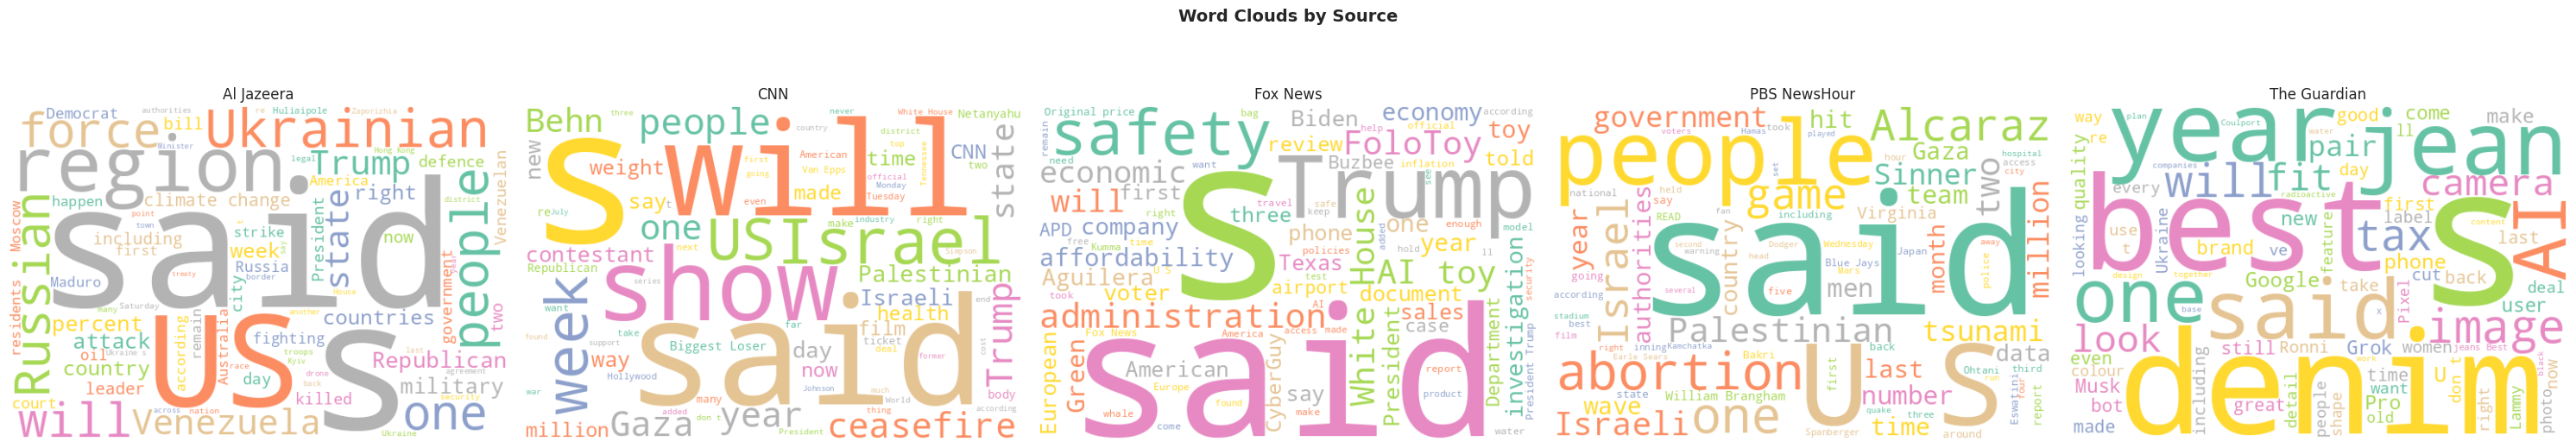

In [28]:
# ============================================================
# Content Analysis — N-grams, Readability, Word Clouds
# ============================================================

# a — TF-IDF top terms per source
print("Computing TF-IDF top terms per source ...")
fig, axes = plt.subplots(1, len(df["source"].unique()), figsize=(24, 8), sharey=False)
if len(df["source"].unique()) == 1:
    axes = [axes]

for ax, src in zip(axes, sorted(df["source"].unique())):
    corpus = df[df["source"] == src]["clean_content"].tolist()
    # min_df=2 to exclude hapax legomena (single-occurrence noise words)
    tfidf = TfidfVectorizer(max_features=20, stop_words="english",
                            ngram_range=(1, 1), max_df=0.9, min_df=2)
    try:
        mat = tfidf.fit_transform(corpus)
        scores = dict(zip(tfidf.get_feature_names_out(),
                          mat.mean(axis=0).A1))
        sorted_terms = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:15]
        terms, vals = zip(*sorted_terms) if sorted_terms else ([], [])
        ax.barh(list(terms), list(vals), color=sns.color_palette("Set2", 15))
        ax.invert_yaxis()
    except ValueError:
        ax.text(0.5, 0.5, "Not enough data", ha="center", va="center")
    ax.set_title(src, fontsize=11)

plt.suptitle("Top TF-IDF Unigrams by Source", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# b — Top bigrams per source
print("Computing top bigrams per source ...")
fig, axes = plt.subplots(1, len(df["source"].unique()), figsize=(24, 8), sharey=False)
if len(df["source"].unique()) == 1:
    axes = [axes]

for ax, src in zip(axes, sorted(df["source"].unique())):
    corpus = df[df["source"] == src]["clean_content"].tolist()
    cv = CountVectorizer(ngram_range=(2, 2), stop_words="english",
                         max_features=15, max_df=0.9, min_df=2)
    try:
        mat = cv.fit_transform(corpus)
        freqs = dict(zip(cv.get_feature_names_out(), mat.sum(axis=0).A1))
        sorted_bg = sorted(freqs.items(), key=lambda x: x[1], reverse=True)[:15]
        terms, vals = zip(*sorted_bg) if sorted_bg else ([], [])
        ax.barh(list(terms), list(vals), color=sns.color_palette("Set3", 15))
        ax.invert_yaxis()
    except ValueError:
        ax.text(0.5, 0.5, "Not enough data", ha="center", va="center")
    ax.set_title(src, fontsize=11)

plt.suptitle("Top Bigrams by Source", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# c — Readability scores
# filter to articles with >= 100 words to avoid extreme/unreliable
# Flesch scores from very short texts (textstat produces wild values
# for 1-5 word inputs, e.g. scores > 120 or deeply negative).
print("Computing readability scores ...")
READABILITY_MIN_WORDS = 100
read_mask = df["clean_word_count"] >= READABILITY_MIN_WORDS
n_short = (~read_mask).sum()
print(f"  Excluding {n_short} articles with < {READABILITY_MIN_WORDS} words from readability.")

df["flesch_reading_ease"] = np.nan
df["flesch_kincaid_grade"] = np.nan
df.loc[read_mask, "flesch_reading_ease"] = df.loc[read_mask, "clean_content"].apply(
    lambda t: textstat.flesch_reading_ease(t) if t else np.nan
)
df.loc[read_mask, "flesch_kincaid_grade"] = df.loc[read_mask, "clean_content"].apply(
    lambda t: textstat.flesch_kincaid_grade(t) if t else np.nan
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
df.boxplot(column="flesch_reading_ease", by="source", ax=axes[0],
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0].set_title("Flesch Reading Ease by Source")
axes[0].set_xlabel("")

df.boxplot(column="flesch_kincaid_grade", by="source", ax=axes[1],
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].set_title("Flesch-Kincaid Grade Level by Source")
axes[1].set_xlabel("")

plt.suptitle("Readability by Source", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nReadability Statistics by Source (articles with ≥ 100 words):")
print(df.groupby("source")[["flesch_reading_ease", "flesch_kincaid_grade"]]
      .describe().round(1).to_string())

# d — Word clouds per source
print("\nGenerating word clouds ...")
n_sources = len(df["source"].unique())
fig, axes = plt.subplots(1, n_sources, figsize=(6 * n_sources, 6))
if n_sources == 1:
    axes = [axes]

for ax, src in zip(axes, sorted(df["source"].unique())):
    text = " ".join(df[df["source"] == src]["clean_content"].tolist())
    if not text.strip():
        ax.text(0.5, 0.5, "No text data", ha="center", va="center",
                transform=ax.transAxes)
        ax.set_title(src, fontsize=12)
        ax.axis("off")
        continue
    try:
        # use STOPWORDS constant instead of instantiating a throwaway WordCloud
        wc = WordCloud(width=600, height=400, max_words=80,
                       background_color="white", colormap="Set2",
                       stopwords=STOPWORDS).generate(text)
        ax.imshow(wc, interpolation="bilinear")
    except ValueError:
        ax.text(0.5, 0.5, "Could not generate", ha="center", va="center",
                transform=ax.transAxes)
    ax.set_title(src, fontsize=12)
    ax.axis("off")

plt.suptitle("Word Clouds by Source", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

2026-02-26 20:44:45,889 - BERTopic - Embedding - Transforming documents to embeddings.


Fitting BERTopic ...
         Results are for pipeline validation only.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

2026-02-26 20:44:47,708 - BERTopic - Embedding - Completed ✓
2026-02-26 20:44:47,709 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-02-26 20:44:54,627 - BERTopic - Dimensionality - Completed ✓
2026-02-26 20:44:54,628 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-02-26 20:44:54,633 - BERTopic - Cluster - Completed ✓
2026-02-26 20:44:54,634 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-02-26 20:44:54,692 - BERTopic - Representation - Completed ✓
2026-02-26 20:44:54,692 - BERTopic - Topic reduction - Reducing number of topics
2026-02-26 20:44:54,699 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-02-26 20:44:54,753 - BERTopic - Representation - Completed ✓
2026-02-26 20:44:54,755 - BERTopic - Topic reduction - Reduced number of topics from 4 to 4



Discovered Topics:
   Topic  Count              Name                                      Representation                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

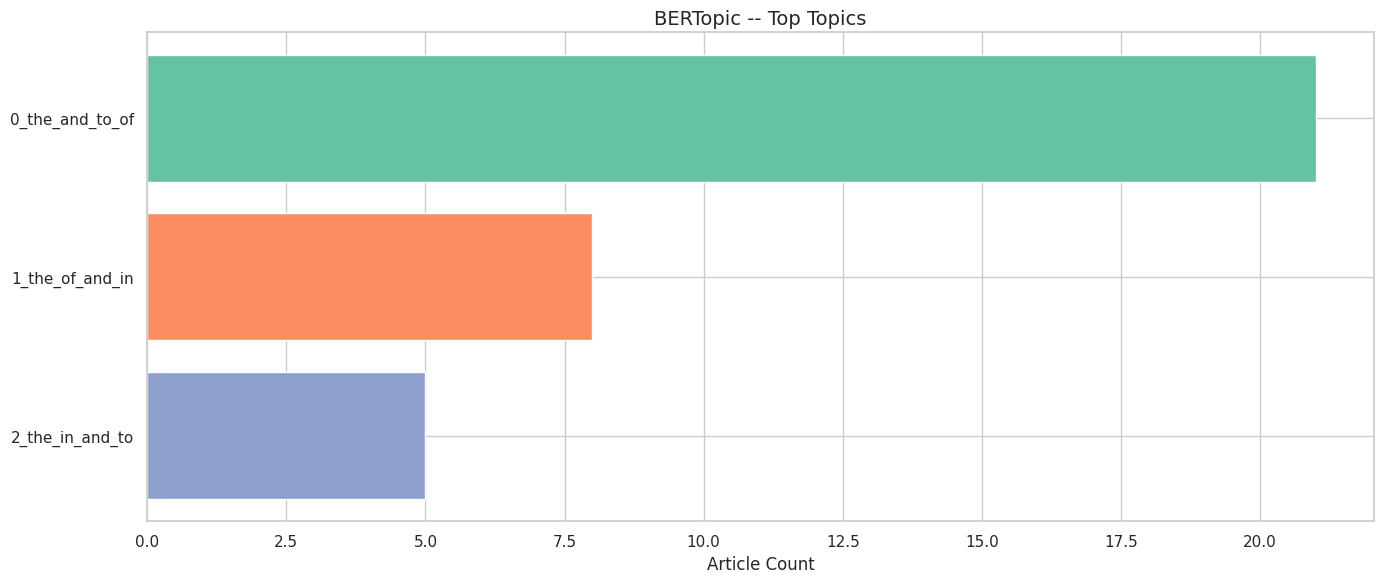

In [29]:
# ============================================================
# BERTopic -- Unsupervised Topic Modeling
# ============================================================

print("Fitting BERTopic ...")

if TEST_MODE:
    print("WARNING: BERTopic with <100 docs produces unreliable topics.")
    print("         Results are for pipeline validation only.")

topic_model = BERTopic(
    language="english",
    min_topic_size=3 if TEST_MODE else 25,
    nr_topics="auto",
    verbose=True,
    # For full mode, reduce UMAP neighbors for tighter clusters
    **({"umap_model": __import__("umap").UMAP(
            n_neighbors=15, n_components=5,
            min_dist=0.0, metric="cosine", random_state=RANDOM_STATE
        )} if not TEST_MODE else {}),
)

# Combine title + content for richer embeddings
docs = (df["clean_title"] + ". " + df["clean_content"]).tolist()
topics, probs = topic_model.fit_transform(docs)

df["bertopic_topic"] = topics

topic_info = topic_model.get_topic_info()
print("\nDiscovered Topics:")
print(topic_info.to_string())

# a -- Topic frequency bar chart
fig, ax = plt.subplots(figsize=(14, max(6, len(topic_info) * 0.4)))
valid_topics = topic_info[topic_info["Topic"] != -1].head(20)
if len(valid_topics) > 0:
    ax.barh(
        valid_topics["Name"].astype(str),
        valid_topics["Count"],
        color=sns.color_palette("Set2", len(valid_topics)),
    )
    ax.invert_yaxis()
    ax.set_xlabel("Article Count")
    ax.set_title("BERTopic -- Top Topics")
else:
    ax.text(0.5, 0.5, "No topics discovered (try more data)",
            ha="center", va="center")
plt.tight_layout()
plt.show()

# b -- BERTopic built-in visualisations
try:
    fig_topics = topic_model.visualize_barchart(top_n_topics=min(10, len(valid_topics)))
    fig_topics.show()
except Exception:
    print("BERTopic barchart visualisation skipped (not enough topics).")

try:
    fig_heatmap = topic_model.visualize_heatmap()
    fig_heatmap.show()
except Exception:
    print("BERTopic heatmap visualisation skipped (not enough topics).")

# Free memory
del topic_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

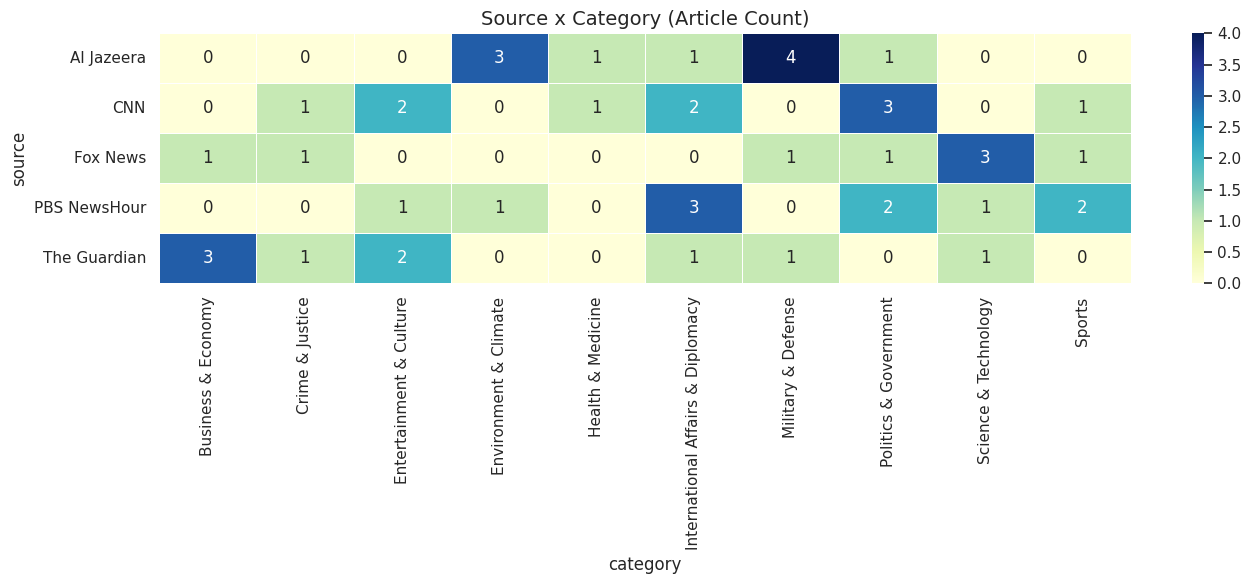

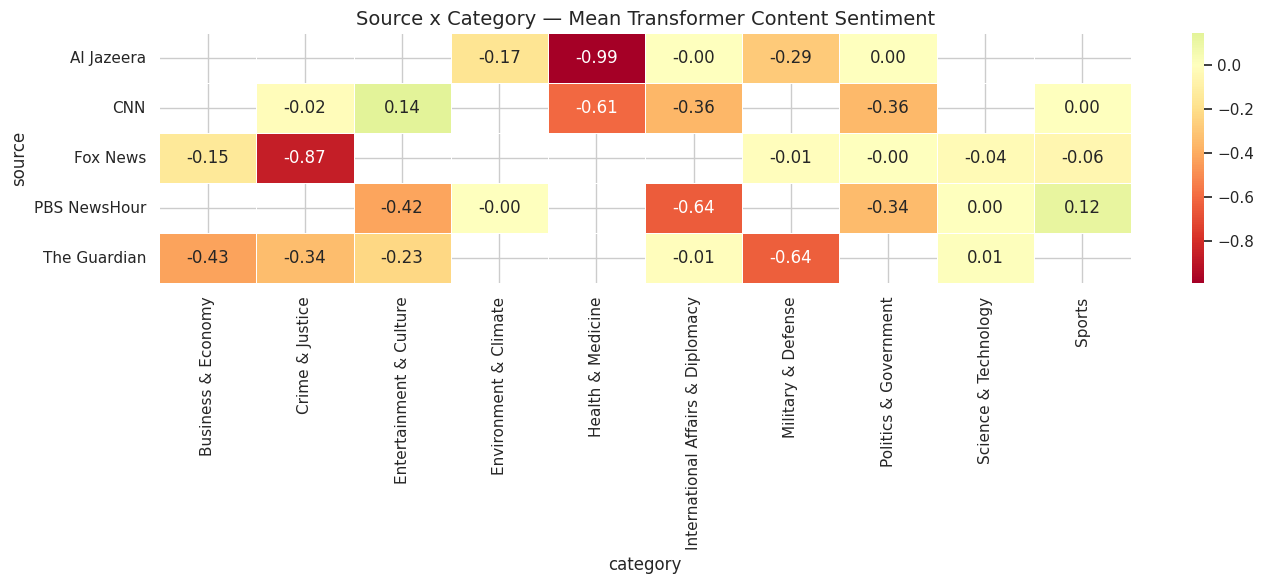

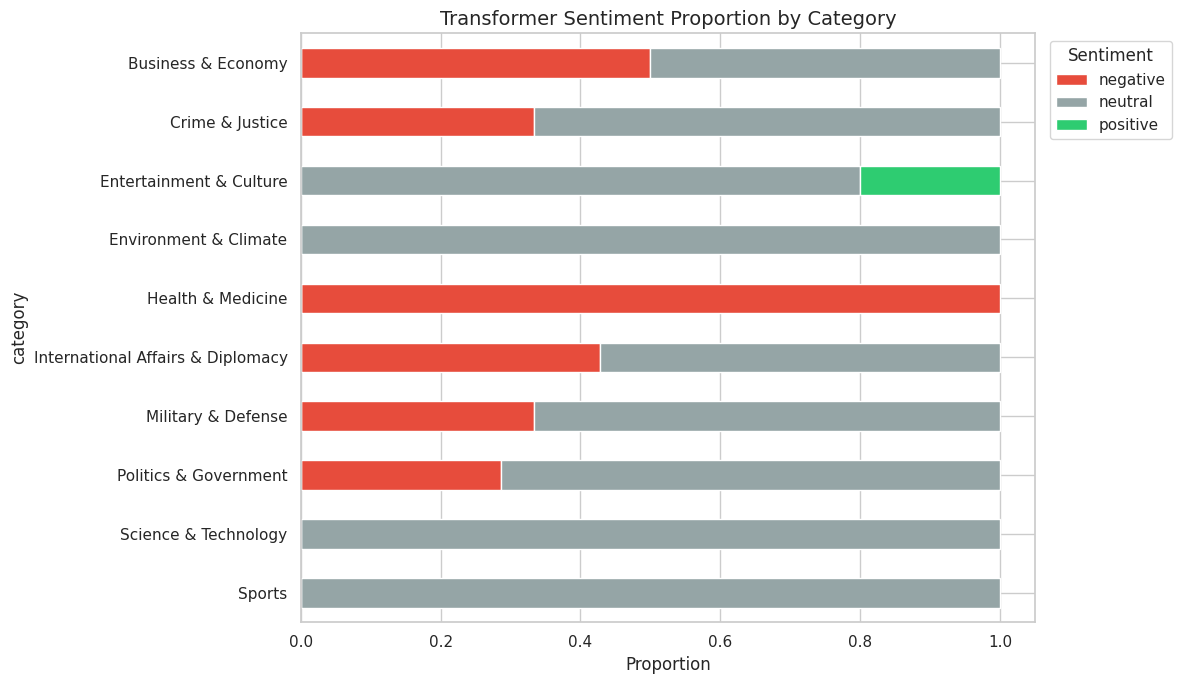

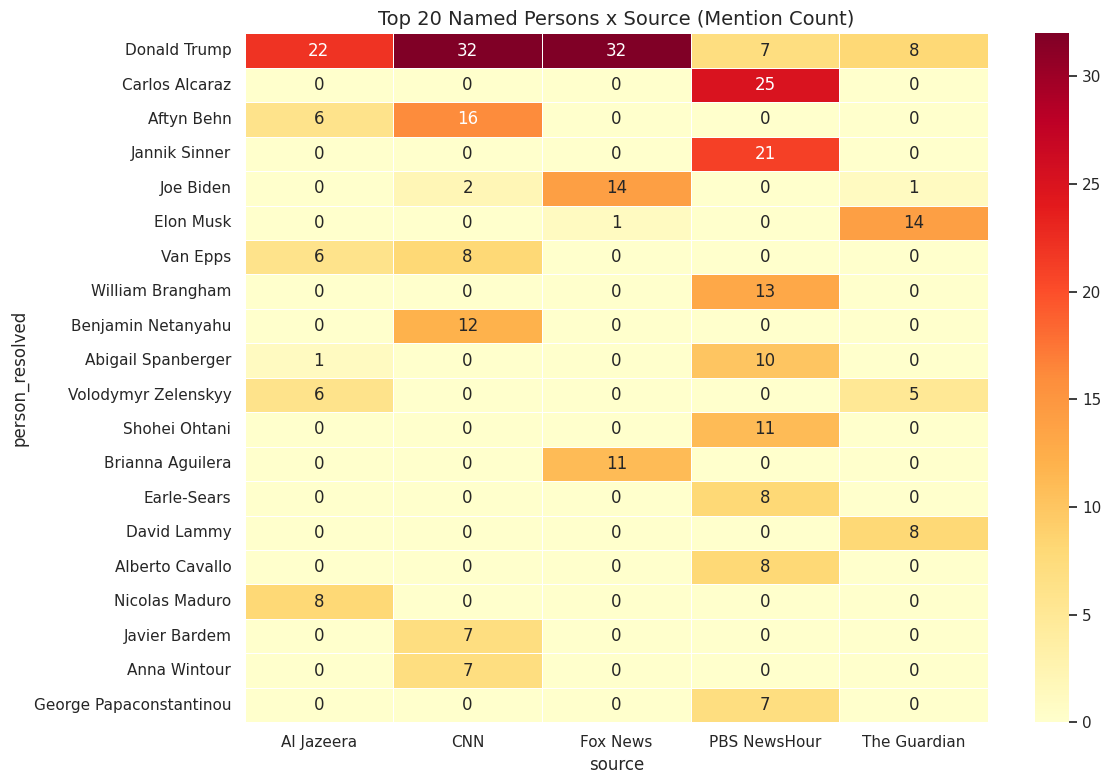

In [30]:
# ============================================================
# Cross-Analysis Heatmaps
# ============================================================

# a — Source x Category (article count)
ct_src_cat = pd.crosstab(df["source"], df["category"])
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(ct_src_cat, annot=True, fmt="d", cmap="YlGnBu", ax=ax, linewidths=0.5)
ax.set_title("Source x Category (Article Count)")
plt.tight_layout()
plt.show()

# b — Source x Category (mean Transformer sentiment)
pivot_sent = df.pivot_table(
    index="source", columns="category",
    values="trans_content_compound", aggfunc="mean",
)
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(pivot_sent, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            ax=ax, linewidths=0.5)
ax.set_title("Source x Category — Mean Transformer Content Sentiment")
plt.tight_layout()
plt.show()

# c — Category x Sentiment label (proportion) — Transformer
cat_sent = pd.crosstab(df["category"], df["trans_content_label"], normalize="index")
fig, ax = plt.subplots(figsize=(12, 7))
cat_sent.plot(kind="barh", stacked=True, ax=ax,
              color={"negative": "#e74c3c", "neutral": "#95a5a6", "positive": "#2ecc71"})
ax.set_title("Transformer Sentiment Proportion by Category")
ax.set_xlabel("Proportion")
ax.legend(title="Sentiment", bbox_to_anchor=(1.01, 1))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# d — Top figures x Source co-occurrence heatmap
if len(persons_df) > 0 and "person_resolved" in persons_df.columns:
    top20 = person_freq.head(20).index.tolist()
    co_df = persons_df[persons_df["person_resolved"].isin(top20)]
    ct_fig_src = pd.crosstab(co_df["person_resolved"], co_df["source"])
    ct_fig_src = ct_fig_src.loc[[f for f in top20 if f in ct_fig_src.index]]

    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(ct_fig_src, annot=True, fmt="d", cmap="YlOrRd", ax=ax, linewidths=0.5)
    ax.set_title("Top 20 Named Persons x Source (Mention Count)")
    plt.tight_layout()
    plt.show()

In [31]:
# ============================================================
# Statistical Significance Tests
# ============================================================

print("=" * 60)
print("STATISTICAL SIGNIFICANCE TESTS")
print("=" * 60)

def cramers_v(confusion_matrix_array):
    """Calculate Cramer's V from a confusion/contingency matrix."""
    chi2 = stats.chi2_contingency(confusion_matrix_array)[0]
    n = confusion_matrix_array.sum().sum()
    min_dim = min(confusion_matrix_array.shape) - 1
    if min_dim == 0 or n == 0:
        return 0.0
    return np.sqrt(chi2 / (n * min_dim))


def pairwise_mannwhitney(df_in, group_col, value_col, alpha=BONFERRONI_ALPHA):
    """Run pairwise Mann-Whitney U tests with Bonferroni correction."""
    groups = sorted(df_in[group_col].unique())
    results = []
    for a, b in combinations(groups, 2):
        vals_a = df_in[df_in[group_col] == a][value_col].dropna()
        vals_b = df_in[df_in[group_col] == b][value_col].dropna()
        if len(vals_a) < 2 or len(vals_b) < 2:
            continue
        stat, p = stats.mannwhitneyu(vals_a, vals_b, alternative="two-sided")
        # Effect size: rank-biserial correlation r = 1 - 2U/(n1*n2)
        n1, n2 = len(vals_a), len(vals_b)
        r_effect = 1 - (2 * stat) / (n1 * n2)
        results.append({
            "Group A": a,
            "Group B": b,
            "U statistic": stat,
            "p-value": p,
            "p < alpha_bonf": "Yes" if p < alpha else "No",
            "Effect size (r)": round(r_effect, 4),
            "n_A": n1,
            "n_B": n2,
        })
    return pd.DataFrame(results)


# -- Transformer Sentiment across Sources --
print("\n--- Transformer Content Sentiment across Sources ---")
source_groups_t = [
    group["trans_content_compound"].dropna().values
    for _, group in df.groupby("source")
]

if len(source_groups_t) >= 2:
    h_stat, h_p = stats.kruskal(*source_groups_t)
    print(f"Kruskal-Wallis H = {h_stat:.2f}, p = {h_p:.2e}")
    print(f"  Significant at alpha={ALPHA}: {'Yes' if h_p < ALPHA else 'No'}")

    if h_p < ALPHA:
        print("\n  Pairwise Mann-Whitney U (Bonferroni-corrected):")
        pw = pairwise_mannwhitney(df, "source", "trans_content_compound")
        print(pw.to_string(index=False))


# -- Transformer Sentiment across Leanings --
print("\n--- Transformer Content Sentiment across Leanings ---")
leaning_groups = [
    group["trans_content_compound"].dropna().values
    for _, group in df.groupby("leaning")
]

if len(leaning_groups) >= 2:
    h_stat, h_p = stats.kruskal(*leaning_groups)
    print(f"Kruskal-Wallis H = {h_stat:.2f}, p = {h_p:.2e}")
    print(f"  Significant at alpha={ALPHA}: {'Yes' if h_p < ALPHA else 'No'}")
    print("  NOTE: 'leaning' is assigned at the outlet level, not article level.")
    print("  This test effectively compares outlet groups, not individual article ideology.")

    if h_p < ALPHA:
        n_lean_pairs = len(list(combinations(df["leaning"].unique(), 2)))
        bonf_lean = ALPHA / max(n_lean_pairs, 1)
        pw = pairwise_mannwhitney(df, "leaning", "trans_content_compound", alpha=bonf_lean)
        print(f"\n  Pairwise Mann-Whitney U (Bonferroni alpha={bonf_lean:.4f}):")
        print(pw.to_string(index=False))


# -- Category Distribution across Sources (Chi-Square) --
print("\n--- Category Distribution across Sources ---")
ct_src_cat = pd.crosstab(df["source"], df["category"])

if ct_src_cat.shape[0] >= 2 and ct_src_cat.shape[1] >= 2:
    chi2, p_chi, dof, expected = stats.chi2_contingency(ct_src_cat)
    v = cramers_v(ct_src_cat)
    print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p_chi:.2e}")
    print(f"Cramer's V = {v:.3f}")
    if v < 0.1:
        v_interp = "Negligible"
    elif v < 0.3:
        v_interp = "Small"
    elif v < 0.5:
        v_interp = "Medium"
    else:
        v_interp = "Large"
    print(f"  Effect size interpretation: {v_interp}")

    # >>> PEER-REVIEW: chi-square validity check
    n_low_expected = (expected < 5).sum()
    pct_low = n_low_expected / expected.size * 100
    if pct_low > 20:
        print(f"  WARNING: {pct_low:.0f}% of expected cell counts < 5 "
              f"({n_low_expected}/{expected.size}). Chi-square may be unreliable.")
        print(f"  Consider Fisher's exact test or collapsing sparse categories.")
    elif n_low_expected > 0:
        print(f"  Note: {n_low_expected}/{expected.size} expected counts < 5 ({pct_low:.0f}%)")


# -- Sentiment Label Distribution across Sources (Chi-Square) --
print("\n--- Sentiment Label Distribution across Sources ---")
ct = pd.crosstab(df["source"], df["trans_content_label"])
if ct.shape[0] >= 2 and ct.shape[1] >= 2:
    chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
    v = cramers_v(ct)
    print(f"\n  Transformer: chi2 = {chi2:.2f}, df = {dof}, p = {p_chi:.2e}, "
          f"Cramer's V = {v:.3f}")


# -- Readability across Sources --
print("\n--- Readability (Flesch Reading Ease) across Sources ---")
if "flesch_reading_ease" in df.columns:
    read_groups = [
        group["flesch_reading_ease"].dropna().values
        for _, group in df.groupby("source")
    ]
    read_groups = [g for g in read_groups if len(g) >= 2]

    if len(read_groups) >= 2:
        h_stat, h_p = stats.kruskal(*read_groups)
        print(f"Kruskal-Wallis H = {h_stat:.2f}, p = {h_p:.2e}")
        print(f"  Significant at alpha={ALPHA}: {'Yes' if h_p < ALPHA else 'No'}")

        if h_p < ALPHA:
            pw = pairwise_mannwhitney(df, "source", "flesch_reading_ease")
            print("\n  Pairwise Mann-Whitney U (Bonferroni-corrected):")
            print(pw.to_string(index=False))


# -- Correlation: Sentiment vs Readability --
print("\n--- Correlation: Sentiment vs Readability ---")
if "flesch_reading_ease" in df.columns:
    sent_col = "trans_content_compound"
    mask = df[sent_col].notna() & df["flesch_reading_ease"].notna()
    if mask.sum() >= 10:
        rho, p = stats.spearmanr(df.loc[mask, sent_col],
                                 df.loc[mask, "flesch_reading_ease"])
        print(f"  Transformer compound vs Flesch RE: rho = {rho:.3f}, p = {p:.2e}")


# -- Correlation: Word Count vs Sentiment --
print("\n--- Correlation: Word Count vs Sentiment ---")
sent_col = "trans_content_compound"
mask = df[sent_col].notna() & df["clean_word_count"].notna()
if mask.sum() >= 10:
    rho, p = stats.spearmanr(df.loc[mask, sent_col],
                             df.loc[mask, "clean_word_count"])
    print(f"  Transformer compound vs word count: rho = {rho:.3f}, p = {p:.2e}")


# -- Figure Coverage across Sources (Chi-Square) --
if len(persons_df) > 0 and "person_resolved" in persons_df.columns:
    print("\n--- Top Figure Coverage across Sources ---")
    all_sources = sorted(df["source"].unique())
    expected_prop = df["source"].value_counts(normalize=True).reindex(all_sources, fill_value=0)
    top10 = person_freq.head(10).index.tolist()

    for figure in top10[:5]:  # top 5 for brevity
        fig_mask = persons_df["person_resolved"] == figure
        total_mentions = fig_mask.sum()
        if total_mentions < 5:
            continue

        # Observed mentions per source — reindex to ALL sources with fill 0
        observed = (persons_df.loc[fig_mask]
                    .groupby("source").size()
                    .reindex(all_sources, fill_value=0))

        # Expected mentions if coverage is proportional to source article counts
        expected_counts = expected_prop * total_mentions

        # Need at least 2 sources with expected > 0 for a meaningful test
        valid = expected_counts > 0
        if valid.sum() < 2:
            continue

        chi2, p = stats.chisquare(observed[valid].values,
                                  expected_counts[valid].values)
        print(f"  {figure:<30s}  chi2 = {chi2:.1f}, p = {p:.2e} "
              f"(proportional coverage test, {total_mentions} mentions)")


# -- Sentence vs Article Sentiment Statistical Test --
if ("_sentence_sentiment_available" in dir() and _sentence_sentiment_available
        and len(_sent_fig) > 0):
    print("\n--- Sentence vs Article Sentiment (Ecological Fallacy Test) ---")
    comparison_df_stat = _sent_fig.merge(
        df[["trans_content_compound"]],
        left_on="article_idx", right_index=True, how="left",
    )
    if len(comparison_df_stat) >= 10:
        # Wilcoxon signed-rank test on paired (article, sentence) compounds
        stat_w, p_w = stats.wilcoxon(
            comparison_df_stat["trans_content_compound"],
            comparison_df_stat["sent_compound"],
        )
        mean_diff = (comparison_df_stat["sent_compound"]
                     - comparison_df_stat["trans_content_compound"]).mean()
        print(f"  Wilcoxon signed-rank: W = {stat_w:.1f}, p = {p_w:.2e}")
        print(f"  Mean difference (sentence - article): {mean_diff:+.3f}")
        if p_w < ALPHA:
            print("  Result: Significant difference — sentence-level sentiment differs")
            print("  from article-level, confirming ecological fallacy concern.")
        else:
            print("  Result: No significant difference detected.")

# >>> PEER-REVIEW: Balanced Subsample Robustness Check
# The Guardian dominates the full dataset (~55%). Unbalanced source counts
# can drive spurious significance or mask real differences. We downsample
# each source to the size of the smallest source and re-run key omnibus tests.
print("\n--- Balanced Subsample Robustness Check ---")
source_counts = df["source"].value_counts()
print(f"  Full dataset source distribution:")
for src, n in source_counts.items():
    print(f"    {src}: {n} ({n/len(df)*100:.1f}%)")

min_source_n = source_counts.min()
imbalance_ratio = source_counts.max() / max(min_source_n, 1)
print(f"  Imbalance ratio (largest/smallest): {imbalance_ratio:.1f}x")

if min_source_n >= 10:
    df_balanced = (
        df.groupby("source", group_keys=False)
        .apply(lambda x: x.sample(min_source_n, random_state=RANDOM_STATE))
    )
    print(f"\n  Balanced subsample: {min_source_n} articles per source "
          f"({len(df_balanced)} total)")

    # Re-run Kruskal-Wallis on balanced sample
    balanced_groups = [
        group["trans_content_compound"].dropna().values
        for _, group in df_balanced.groupby("source")
    ]
    if len(balanced_groups) >= 2 and all(len(g) >= 2 for g in balanced_groups):
        h_stat_b, h_p_b = stats.kruskal(*balanced_groups)
        print(f"  Sentiment (Kruskal-Wallis, balanced): H = {h_stat_b:.2f}, p = {h_p_b:.2e}")
        sig_b = "Yes" if h_p_b < ALPHA else "No"
        print(f"    Significant at alpha={ALPHA}: {sig_b}")

        if h_p_b < ALPHA:
            pw_b = pairwise_mannwhitney(df_balanced, "source", "trans_content_compound")
            print(f"\n    Pairwise Mann-Whitney U (balanced, Bonferroni-corrected):")
            print(pw_b.to_string(index=False))

    # Balanced category chi-square
    ct_bal = pd.crosstab(df_balanced["source"], df_balanced["category"])
    if ct_bal.shape[0] >= 2 and ct_bal.shape[1] >= 2:
        chi2_b, p_b, dof_b, exp_b = stats.chi2_contingency(ct_bal)
        v_b = cramers_v(ct_bal)
        print(f"  Categories (chi-square, balanced): chi2 = {chi2_b:.2f}, "
              f"p = {p_b:.2e}, Cramer\'s V = {v_b:.3f}")
        n_low_b = (exp_b < 5).sum()
        if n_low_b / exp_b.size * 100 > 20:
            print(f"    WARNING: {n_low_b}/{exp_b.size} expected counts < 5")

    # Balanced readability
    if "flesch_reading_ease" in df_balanced.columns:
        read_groups_b = [
            group["flesch_reading_ease"].dropna().values
            for _, group in df_balanced.groupby("source")
        ]
        read_groups_b = [g for g in read_groups_b if len(g) >= 2]
        if len(read_groups_b) >= 2:
            h_r, p_r = stats.kruskal(*read_groups_b)
            print(f"  Readability (Kruskal-Wallis, balanced): H = {h_r:.2f}, p = {p_r:.2e}")
else:
    print(f"  Smallest source has only {min_source_n} articles; "
          f"balanced subsample skipped (need >= 10).")

print("\n" + "=" * 60)
print("Statistical tests complete.")
print("=" * 60)



STATISTICAL SIGNIFICANCE TESTS

--- Transformer Content Sentiment across Sources ---
Kruskal-Wallis H = 1.20, p = 8.78e-01
  Significant at alpha=0.05: No

--- Transformer Content Sentiment across Leanings ---
Kruskal-Wallis H = 1.09, p = 5.80e-01
  Significant at alpha=0.05: No
  NOTE: 'leaning' is assigned at the outlet level, not article level.
  This test effectively compares outlet groups, not individual article ideology.

--- Category Distribution across Sources ---
Chi-square = 51.48, df = 36, p = 4.55e-02
Cramer's V = 0.523
  Effect size interpretation: Large
  Consider Fisher's exact test or collapsing sparse categories.

--- Sentiment Label Distribution across Sources ---

  Transformer: chi2 = 5.32, df = 8, p = 7.23e-01, Cramer's V = 0.238

--- Readability (Flesch Reading Ease) across Sources ---
Kruskal-Wallis H = 6.77, p = 1.48e-01
  Significant at alpha=0.05: No

--- Correlation: Sentiment vs Readability ---
  Transformer compound vs Flesch RE: rho = 0.452, p = 1.44e-03

